# Adam

In [2]:
import math
import torch
from torch import Tensor
from typing import List, Optional
from torch.optim.optimizer import Optimizer


def adam(params: List[Tensor],
         grads: List[Tensor],
         exp_avgs: List[Tensor],
         exp_avg_sqs: List[Tensor],
         max_exp_avg_sqs: List[Tensor],
         state_steps: List[int],
         *,
         amsgrad: bool,
         beta1: float,
         beta2: float,
         lr: float,
         weight_decay: float,
         eps: float):
    r"""Functional API that performs Adam algorithm computation.
    See :class:`~torch.optim.Adam` for details.
    """

    for i, param in enumerate(params):

        grad = grads[i]
        exp_avg = exp_avgs[i]
        exp_avg_sq = exp_avg_sqs[i]
        step = state_steps[i]

        bias_correction1 = 1 - beta1 ** step
        bias_correction2 = 1 - beta2 ** step

        if weight_decay != 0:
            grad = grad.add(param, alpha=weight_decay)

        # Decay the first and second moment running average coefficient
        exp_avg.mul_(beta1).add_(grad, alpha=1 - beta1)
        exp_avg_sq.mul_(beta2).addcmul_(grad, grad.conj(), value=1 - beta2)
        if amsgrad:
            # Maintains the maximum of all 2nd moment running avg. till now
            torch.maximum(max_exp_avg_sqs[i], exp_avg_sq, out=max_exp_avg_sqs[i])
            # Use the max. for normalizing running avg. of gradient
            denom = (max_exp_avg_sqs[i].sqrt() / math.sqrt(bias_correction2)).add_(eps)
        else:
            denom = (exp_avg_sq.sqrt() / math.sqrt(bias_correction2)).add_(eps)

        step_size = lr / bias_correction1

        param.addcdiv_(exp_avg, denom, value=-step_size)


class Adam(Optimizer):
    r"""Implements Adam algorithm.
    It has been proposed in `Adam: A Method for Stochastic Optimization`_.
    The implementation of the L2 penalty follows changes proposed in
    `Decoupled Weight Decay Regularization`_.
    Args:
        params (iterable): iterable of parameters to optimize or dicts defining
            parameter groups
        lr (float, optional): learning rate (default: 1e-3)
        betas (Tuple[float, float], optional): coefficients used for computing
            running averages of gradient and its square (default: (0.9, 0.999))
        eps (float, optional): term added to the denominator to improve
            numerical stability (default: 1e-8)
        weight_decay (float, optional): weight decay (L2 penalty) (default: 0)
        amsgrad (boolean, optional): whether to use the AMSGrad variant of this
            algorithm from the paper `On the Convergence of Adam and Beyond`_
            (default: False)
    .. _Adam\: A Method for Stochastic Optimization:
        https://arxiv.org/abs/1412.6980
    .. _Decoupled Weight Decay Regularization:
        https://arxiv.org/abs/1711.05101
    .. _On the Convergence of Adam and Beyond:
        https://openreview.net/forum?id=ryQu7f-RZ
    """

    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8,
                 weight_decay=0, amsgrad=False):
        if not 0.0 <= lr:
            raise ValueError("Invalid learning rate: {}".format(lr))
        if not 0.0 <= eps:
            raise ValueError("Invalid epsilon value: {}".format(eps))
        if not 0.0 <= betas[0] < 1.0:
            raise ValueError("Invalid beta parameter at index 0: {}".format(betas[0]))
        if not 0.0 <= betas[1] < 1.0:
            raise ValueError("Invalid beta parameter at index 1: {}".format(betas[1]))
        if not 0.0 <= weight_decay:
            raise ValueError("Invalid weight_decay value: {}".format(weight_decay))
        defaults = dict(lr=lr, betas=betas, eps=eps,
                        weight_decay=weight_decay, amsgrad=amsgrad)
        super(Adam, self).__init__(params, defaults)

    def __setstate__(self, state):
        super(Adam, self).__setstate__(state)
        for group in self.param_groups:
            group.setdefault('amsgrad', False)

    @torch.no_grad()
    def step(self, closure=None):
        """Performs a single optimization step.
        Args:
            closure (callable, optional): A closure that reevaluates the model
                and returns the loss.
        """
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()

        for group in self.param_groups:
            params_with_grad = []
            grads = []
            exp_avgs = []
            exp_avg_sqs = []
            max_exp_avg_sqs = []
            state_steps = []
            beta1, beta2 = group['betas']

            for p in group['params']:
                if p.grad is not None:
                    params_with_grad.append(p)
                    if p.grad.is_sparse:
                        raise RuntimeError('Adam does not support sparse gradients, please consider SparseAdam instead')
                    grads.append(p.grad)

                    state = self.state[p]
                    # Lazy state initialization
                    if len(state) == 0:
                        state['step'] = 0
                        # Exponential moving average of gradient values
                        state['exp_avg'] = torch.zeros_like(p, memory_format=torch.preserve_format)
                        # Exponential moving average of squared gradient values
                        state['exp_avg_sq'] = torch.zeros_like(p, memory_format=torch.preserve_format)
                        if group['amsgrad']:
                            # Maintains max of all exp. moving avg. of sq. grad. values
                            state['max_exp_avg_sq'] = torch.zeros_like(p, memory_format=torch.preserve_format)

                    exp_avgs.append(state['exp_avg'])
                    exp_avg_sqs.append(state['exp_avg_sq'])

                    if group['amsgrad']:
                        max_exp_avg_sqs.append(state['max_exp_avg_sq'])

                    # update the steps for each param group update
                    state['step'] += 1
                    # record the step after step update
                    state_steps.append(state['step'])

            adam(params_with_grad,
                 grads,
                 exp_avgs,
                 exp_avg_sqs,
                 max_exp_avg_sqs,
                 state_steps,
                 amsgrad=group['amsgrad'],
                 beta1=beta1,
                 beta2=beta2,
                 lr=group['lr'],
                 weight_decay=group['weight_decay'],
                 eps=group['eps'])
        return loss


# naca_geofno

torch.Size([2490, 221, 51, 2]) torch.Size([2490, 221, 51])
2368033
0 4.480266017999838 0.2997462738752365 0.1040214842557907
1 3.025916719000179 0.10103229415416717 0.10283173680305481
2 3.0344143060001443 0.10080218124389649 0.10282547891139984
3 3.039477858999817 0.10079551374912261 0.10373583734035492
4 3.0451018690000637 0.10074446439743041 0.10280665338039398
5 3.0470242020001024 0.1009717561006546 0.10442658305168152
6 3.0495358870002747 0.10070137083530425 0.10397173881530762
7 3.0539489600000707 0.10069583678245544 0.10352455198764801
8 3.0593610209998587 0.10053937530517579 0.10232499599456787
9 3.0630282849997457 0.10119670057296754 0.10283729791641236
10 3.0682994490002784 0.1006008379459381 0.10289563715457917
11 3.0714813119998325 0.10072363722324372 0.10288892090320587
12 3.0769388989997424 0.10055513274669647 0.10404410600662231
13 3.08374177900032 0.10093361020088196 0.10460181593894959
14 3.0883730179998565 0.1009348521232605 0.10349660754203796
15 3.0915042420001555 0

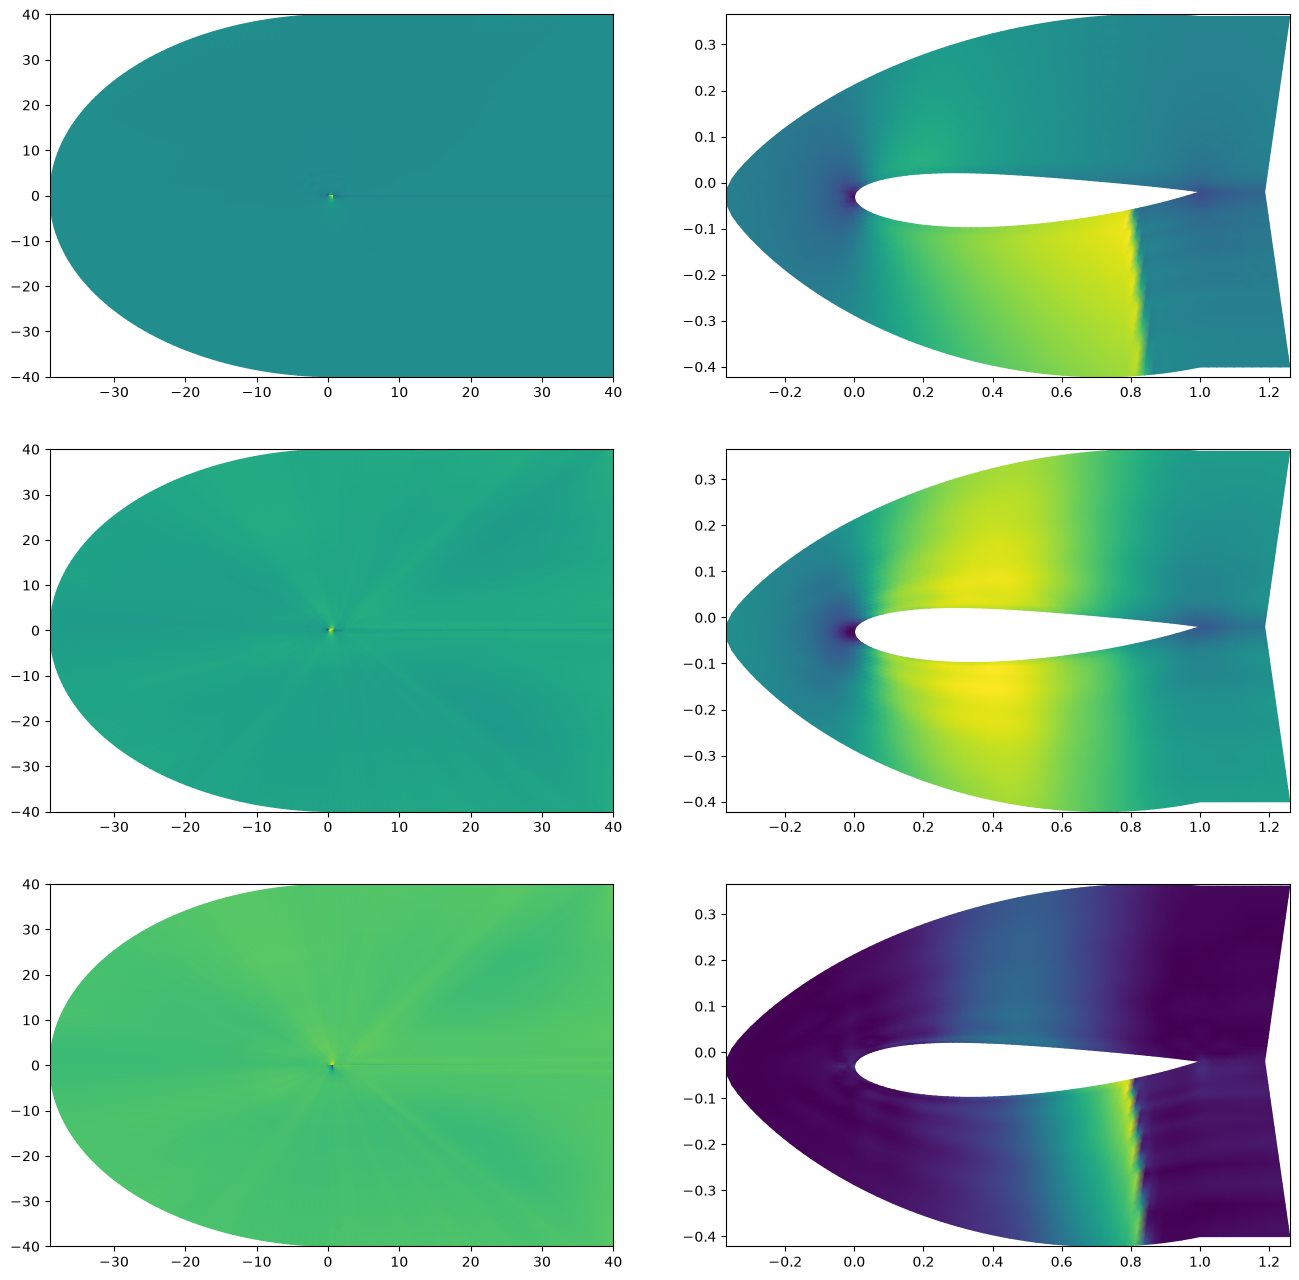

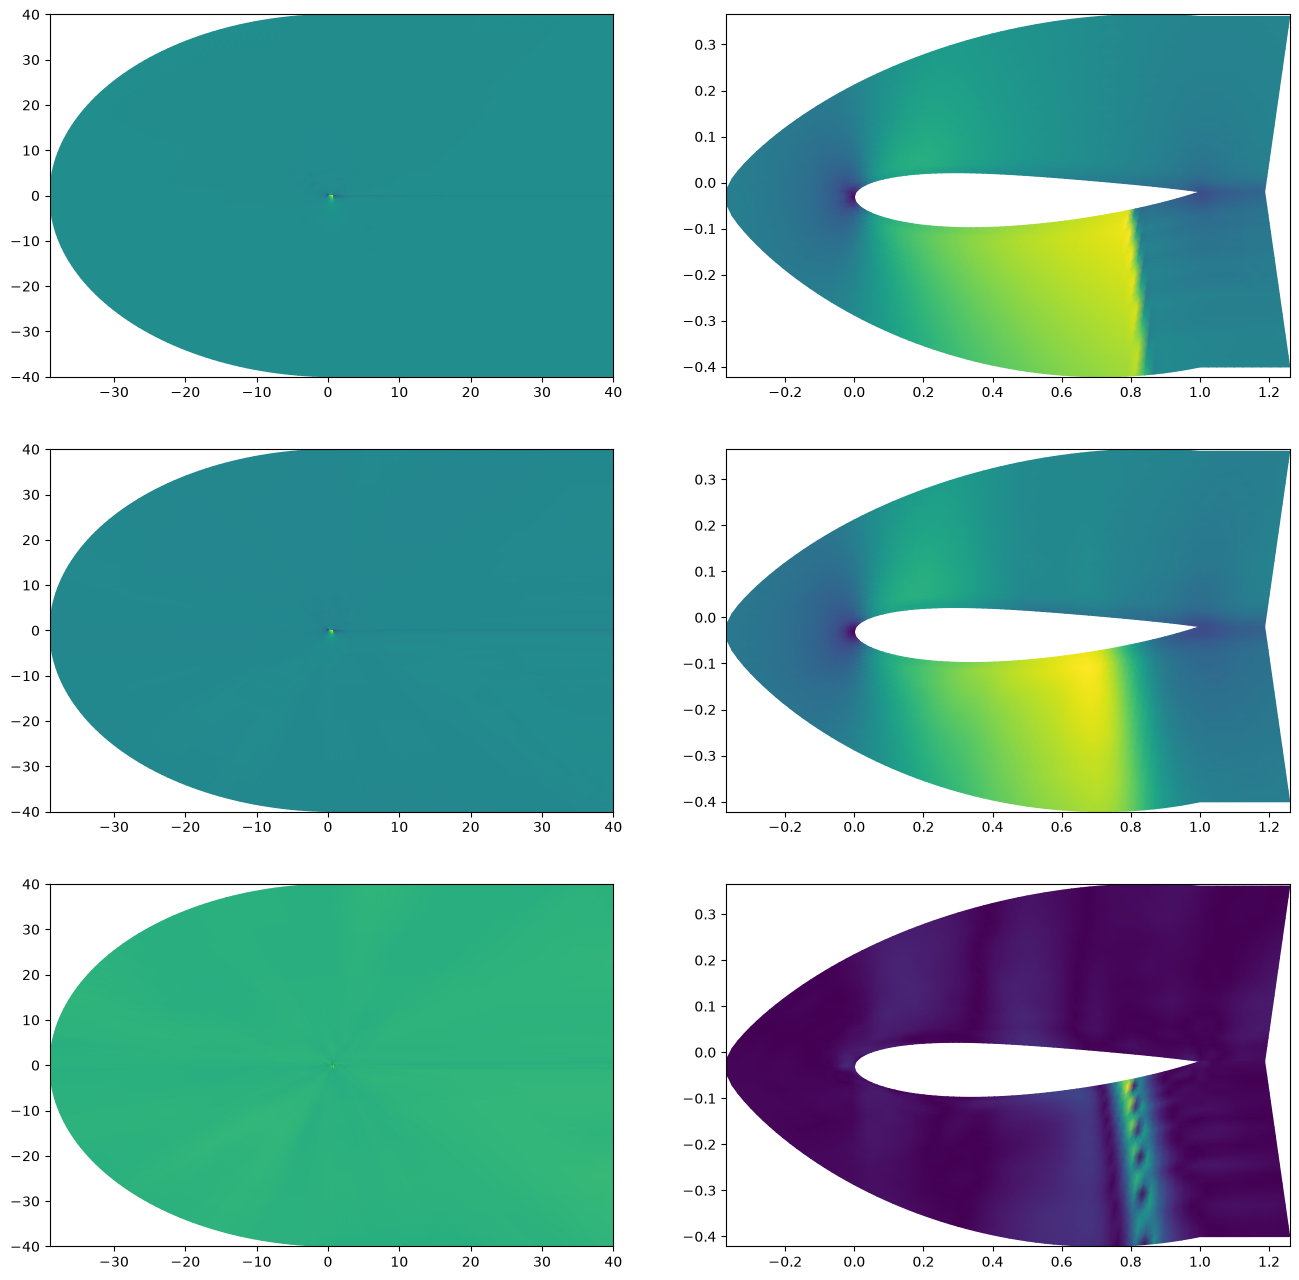

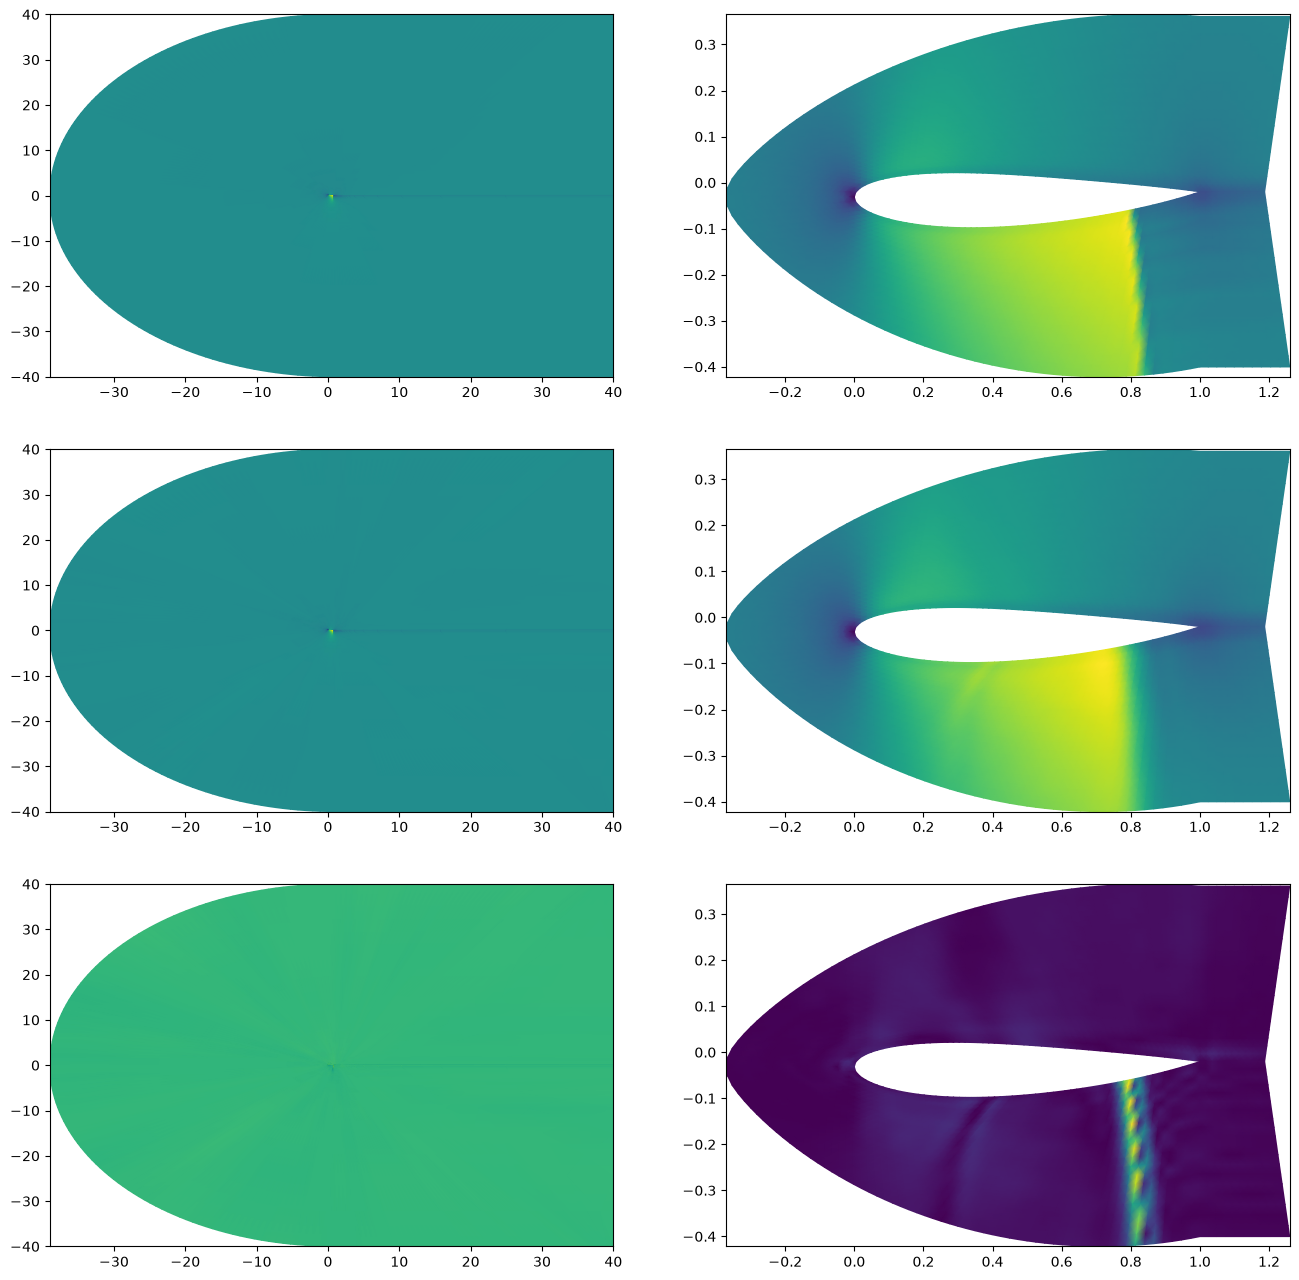

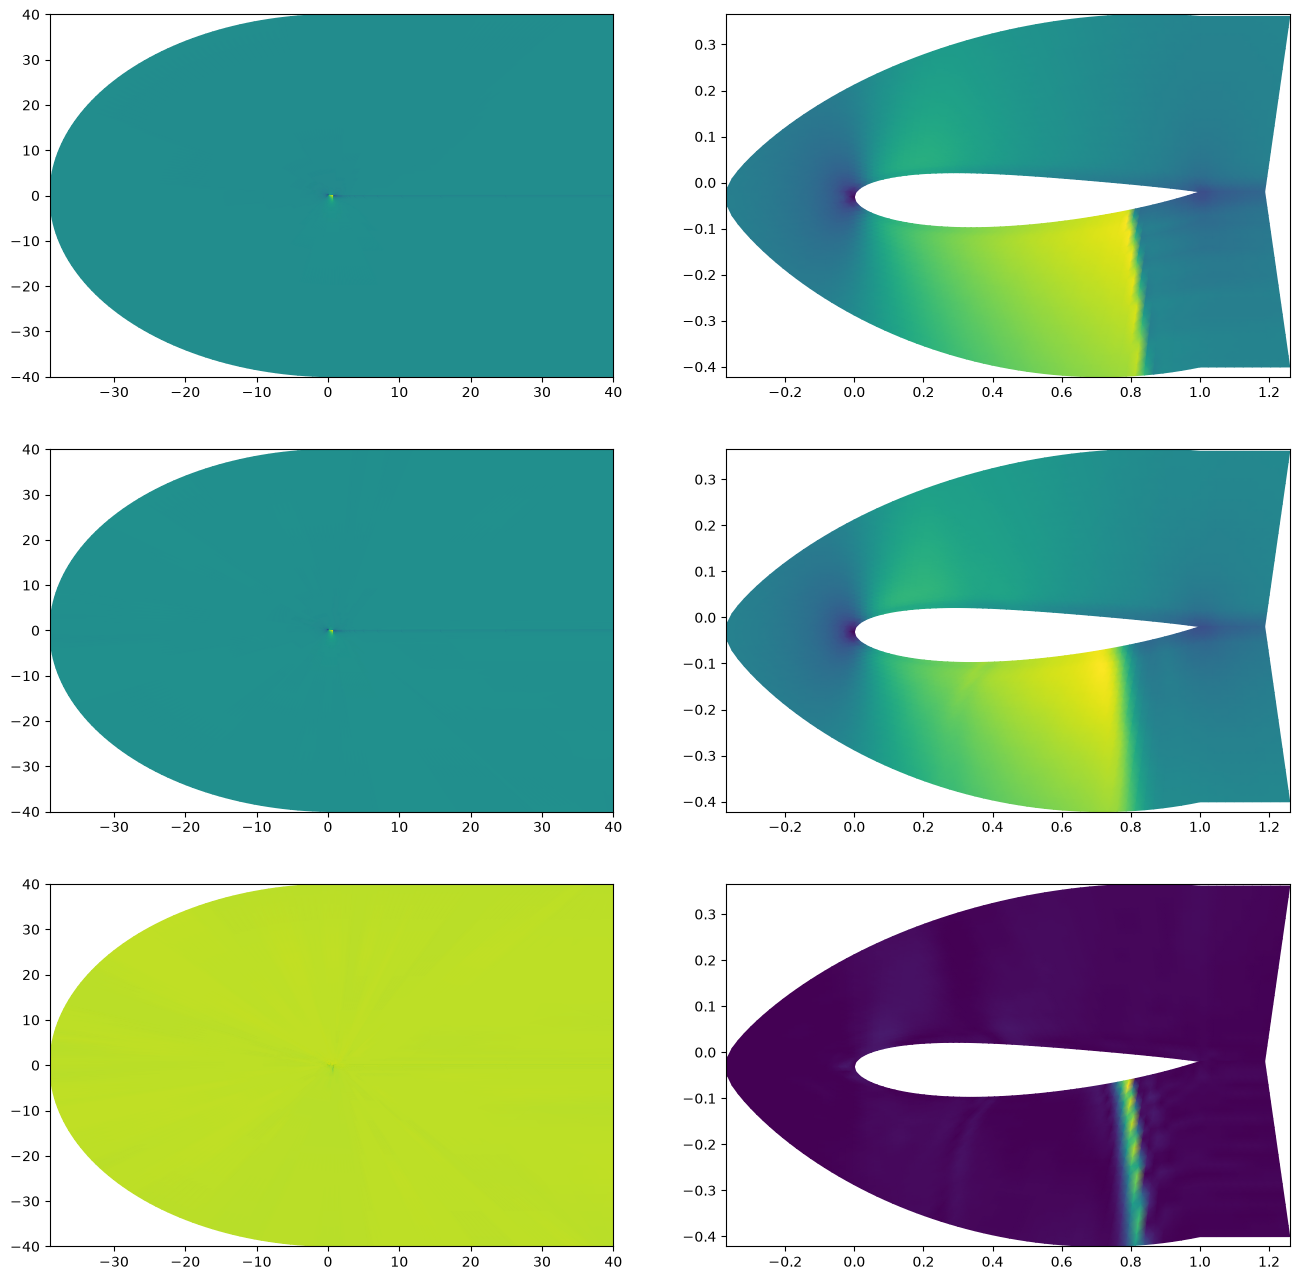

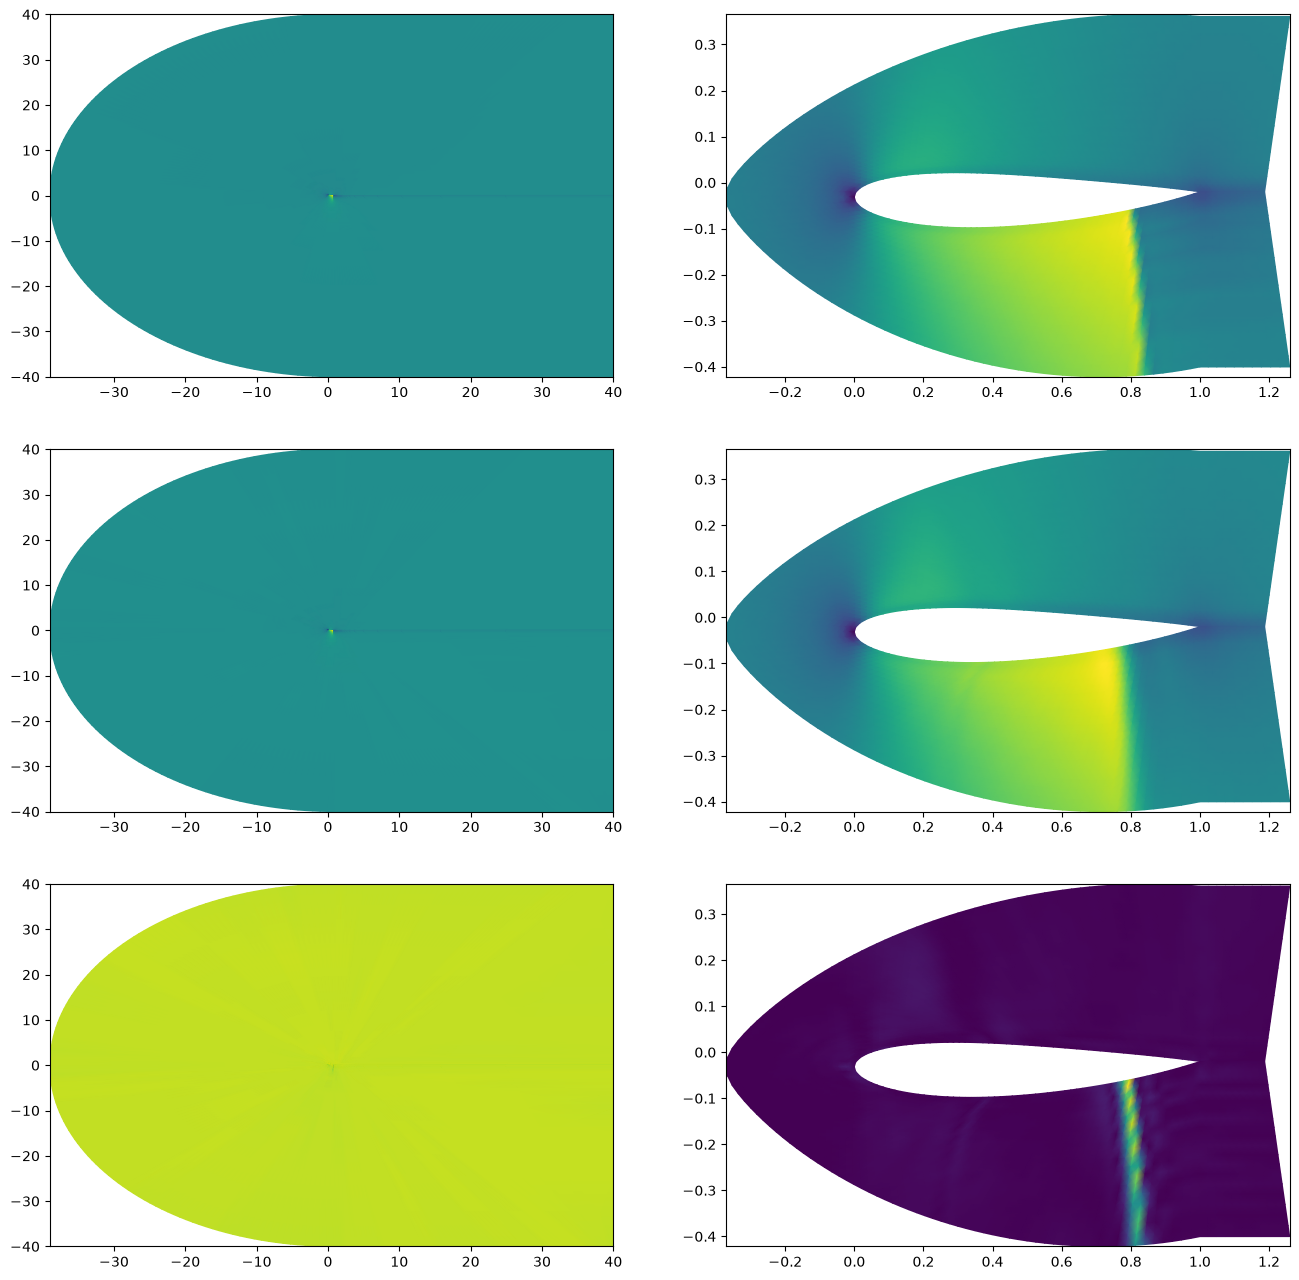

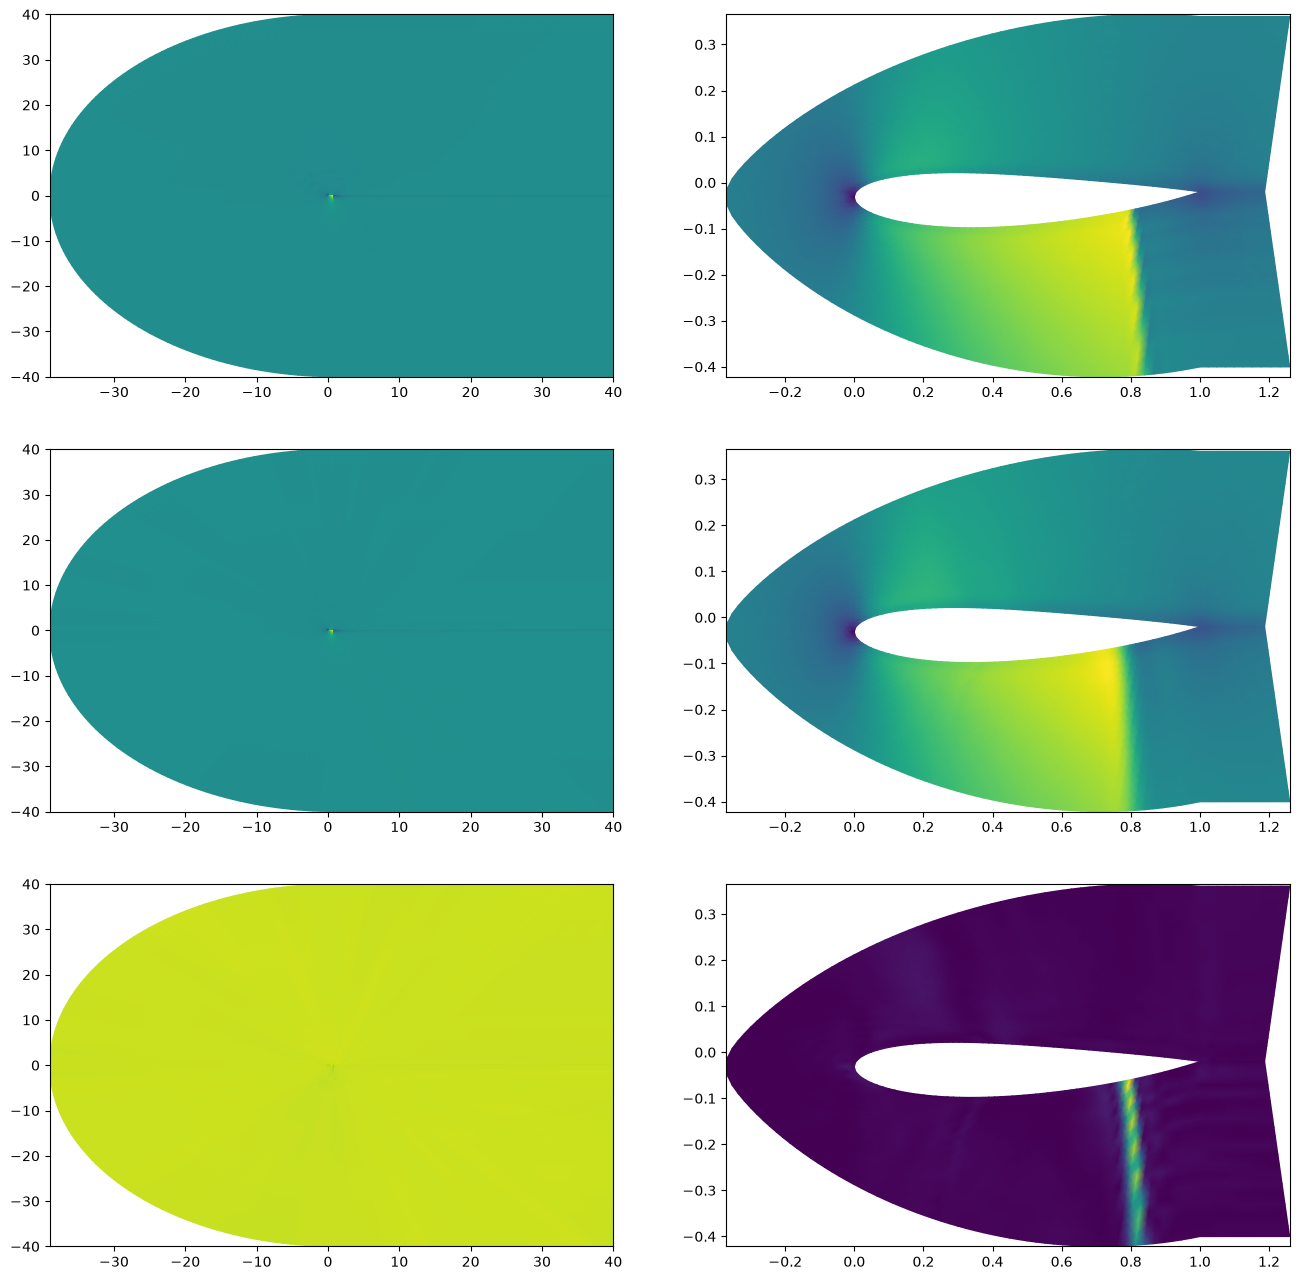

In [4]:
# NACA 翼型流场训练脚本。B 表示批大小，H/W 表示两个网格方向，C 表示通道。
# 输入是随翼型几何变化的物理坐标，FFT 则在结构化网格的索引空间进行。
# 这里使用已有曲线网格的对应关系，没有额外定义可学习的坐标变换网络。
"""
@author: Zongyi Li and Daniel Zhengyu Huang
"""

# F 提供 GELU、补零等函数；plt 用于训练期间的预测结果可视化。
import torch.nn.functional as F
import matplotlib.pyplot as plt
from timeit import default_timer
# 公共工具通过星号导入，还会带入其中的 torch、np、nn 等模块名。
from utilities3 import *
# 使用作者自定义的 Adam；其中复数梯度的二阶矩按 g * conj(g) 累积。
from Adam import Adam

# 固定 PyTorch、NumPy 和 CUDA 随机种子，便于比较重复实验。
# cuDNN 的确定性设置针对其支持的算子，不代表全部硬件上的结果逐位相同。
torch.manual_seed(0)
np.random.seed(0)
torch.cuda.manual_seed(0)
torch.backends.cudnn.deterministic = True

################################################################
# fourier layer
################################################################
# 二维谱卷积：输入 [B,Cin,H,W]，输出 [B,Cout,H,W]。
# 对空间维做 FFT，在选定的低频位置混合通道，再逆变换回空间域。
class SpectralConv2d(nn.Module):
    def __init__(self, in_channels, out_channels, modes1, modes2):
        super(SpectralConv2d, self).__init__()

        """
        2D Fourier layer. It does FFT, linear transform, and Inverse FFT.    
        """

        # in_channels/out_channels 是特征通道数，modes1/modes2 是保留的频率数。
        self.in_channels = in_channels
        self.out_channels = out_channels
        # rfft2 仅压缩最后一个空间维；第一个空间维仍保留正、负频率。
        # 因此第一个方向分别选取频谱开头和末尾的低频区域。
        self.modes1 = modes1  # Number of Fourier modes to multiply, at most floor(N/2) + 1
        self.modes2 = modes2

        # 缩小随机权重的初始化幅度，避免初始谱卷积输出过大。
        self.scale = (1 / (in_channels * out_channels))
        # 权重形状为 [Cin,Cout,modes1,modes2]，每个频率位置有独立的通道混合矩阵。
        # 傅里叶系数是复数，因此可学习权重也使用 torch.cfloat。
        self.weights1 = nn.Parameter(
            self.scale * torch.rand(in_channels, out_channels, self.modes1, self.modes2, dtype=torch.cfloat))
        # 第二组权重用于第一个空间方向的负频率区域，与第一组独立学习。
        self.weights2 = nn.Parameter(
            self.scale * torch.rand(in_channels, out_channels, self.modes1, self.modes2, dtype=torch.cfloat))

    # Complex multiplication
    # einsum 中 i 是输入通道、o 是输出通道，x/y 是频率索引；仅对 i 求和。
    # 不同频率之间不做混合，每个频率分别执行一次复数矩阵乘法。
    def compl_mul2d(self, input, weights):
        # (batch, in_channel, x,y ), (in_channel, out_channel, x,y) -> (batch, out_channel, x,y)
        return torch.einsum("bixy,ioxy->boxy", input, weights)

    def forward(self, x):
        # 此处 x 的布局为 [B,Cin,H,W]，B 为当前批次的样本数。
        batchsize = x.shape[0]
        # Compute Fourier coeffcients up to factor of e^(- something constant)
        # 对最后两个维度做二维实数 FFT，得到 [B,Cin,H,W//2+1] 的复数频谱。
        x_ft = torch.fft.rfft2(x)

        # Multiply relevant Fourier modes
        # 创建输出频谱；未写入的频率保持为零，相当于对这一分支做频率截断。
        out_ft = torch.zeros(batchsize, self.out_channels, x.size(-2), x.size(-1) // 2 + 1, dtype=torch.cfloat,
                             device=x.device)
        # 保留第一个方向开头、第二个方向开头的低频块。
        out_ft[:, :, :self.modes1, :self.modes2] = \
            self.compl_mul2d(x_ft[:, :, :self.modes1, :self.modes2], self.weights1)
        # 第一个方向的负频率位于数组末尾，因此还需写入这个频率块。
        out_ft[:, :, -self.modes1:, :self.modes2] = \
            self.compl_mul2d(x_ft[:, :, -self.modes1:, :self.modes2], self.weights2)

        # Return to physical space
        # 逆 FFT 恢复实数特征场；s 显式指定原尺寸，确保奇数宽度也能正确恢复。
        x = torch.fft.irfft2(out_ft, s=(x.size(-2), x.size(-1)))
        return x


# 整体 FNO：坐标特征提升维度 -> 四层谱卷积/逐点线性分支 -> 标量输出。
# 本脚本实际输入为物理坐标 [X,Y]，并额外拼接计算网格坐标，共 4 个通道。
class FNO2d(nn.Module):
    def __init__(self, modes1, modes2, width):
        super(FNO2d, self).__init__()

        """
        The overall network. It contains 4 layers of the Fourier layer.
        1. Lift the input to the desire channel dimension by self.fc0 .
        2. 4 layers of the integral operators u' = (W + K)(u).
            W defined by self.w; K defined by self.conv .
        3. Project from the channel space to the output space by self.fc1 and self.fc2 .

        input: the solution of the coefficient function and locations (a(x, y), x, y)
        input shape: (batchsize, x=s, y=s, c=3)
        output: the solution 
        output shape: (batchsize, x=s, y=s, c=1)
        """

        self.modes1 = modes1
        self.modes2 = modes2
        self.width = width
        # 在空间维补 8 个零，为 FFT 的周期延拓留出缓冲，输出前再裁去。
        self.padding = 8  # pad the domain if input is non-periodic
        # 这里实际接收 [X,Y,xi,eta] 四个通道；原英文模板中的 3 通道说明
        # 不对应本脚本的数据。Linear 作用于最后一维，输出 width 维特征。
        self.fc0 = nn.Linear(4, self.width)  # input channel is 3: (a(x, y), x, y)

        # 四个谱卷积分支在频域建模全局空间关系。
        self.conv0 = SpectralConv2d(self.width, self.width, self.modes1, self.modes2)
        self.conv1 = SpectralConv2d(self.width, self.width, self.modes1, self.modes2)
        self.conv2 = SpectralConv2d(self.width, self.width, self.modes1, self.modes2)
        self.conv3 = SpectralConv2d(self.width, self.width, self.modes1, self.modes2)
        # 1×1 卷积只混合当前位置的通道，对应公式中的局部线性分支 W。
        self.w0 = nn.Conv2d(self.width, self.width, 1)
        self.w1 = nn.Conv2d(self.width, self.width, 1)
        self.w2 = nn.Conv2d(self.width, self.width, 1)
        self.w3 = nn.Conv2d(self.width, self.width, 1)

        # 输出投影逐点执行 width -> 128 -> 1，得到每个网格点的一个标量。
        self.fc1 = nn.Linear(self.width, 128)
        self.fc2 = nn.Linear(128, 1)

    def forward(self, x):
        # 输入 x 为 [B,H,W,2]，其中两个通道分别是该样本的物理 X/Y 坐标。
        grid = self.get_grid(x.shape, x.device)
        # grid 是规则计算网格坐标 [xi,eta]；拼接后 x 变为 [B,H,W,4]。
        x = torch.cat((x, grid), dim=-1)
        # 提升通道数：[B,H,W,4] -> [B,H,W,width]。
        x = self.fc0(x)
        # 调整为卷积使用的布局 [B,width,H,W]；permute 仅改变维度顺序。
        x = x.permute(0, 3, 1, 2)

        # F.pad 的参数顺序是 [W左,W右,H上,H下]，这里仅在两个方向的末端补零。
        x = F.pad(x, [0, self.padding, 0, self.padding])

        # 第一层：谱分支 K(x) 负责全局关系，逐点分支 W(x) 补充局部通道变换。
        x1 = self.conv0(x)
        x2 = self.w0(x)
        # 两个分支形状一致，逐元素相加后通过 GELU 引入非线性。
        x = x1 + x2
        x = F.gelu(x)

        # 第二层继续对上一层特征执行同样的 K(x) + W(x) 结构。
        x1 = self.conv1(x)
        x2 = self.w1(x)
        x = x1 + x2
        x = F.gelu(x)

        # 第三层谱卷积与逐点线性变换。
        x1 = self.conv2(x)
        x2 = self.w2(x)
        x = x1 + x2
        x = F.gelu(x)

        # 第四层相加后不立即使用 GELU，随后进入输出投影。
        x1 = self.conv3(x)
        x2 = self.w3(x)
        x = x1 + x2

        # 裁掉补零部分，恢复原来的 H/W；随后将通道维移回最后一维。
        x = x[..., :-self.padding, :-self.padding]
        x = x.permute(0, 2, 3, 1)
        # 逐网格点执行两层全连接映射，最终输出形状为 [B,H,W,1]。
        x = self.fc1(x)
        x = F.gelu(x)
        x = self.fc2(x)
        return x

    # 生成与物理坐标不同的计算坐标：沿两个网格索引方向均匀覆盖 [0,1]。
    def get_grid(self, shape, device):
        batchsize, size_x, size_y = shape[0], shape[1], shape[2]
        gridx = torch.tensor(np.linspace(0, 1, size_x), dtype=torch.float)
        # 把一维 xi 扩展到所有样本和所有列，形状为 [B,H,W,1]。
        gridx = gridx.reshape(1, size_x, 1, 1).repeat([batchsize, 1, size_y, 1])
        gridy = torch.tensor(np.linspace(0, 1, size_y), dtype=torch.float)
        # 把一维 eta 扩展到所有样本和所有行，形状同样为 [B,H,W,1]。
        gridy = gridy.reshape(1, 1, size_y, 1).repeat([batchsize, size_x, 1, 1])
        # 拼接为 [B,H,W,2]，并移动到与输入相同的设备。
        return torch.cat((gridx, gridy), dim=-1).to(device)


################################################################
# configs
################################################################
# 原始数据路径相对于程序启动时的工作目录解析。
PATH = "./"
INPUT_X = PATH+'airfoil/naca/NACA_Cylinder_X.npy'
INPUT_Y = PATH+'airfoil/naca/NACA_Cylinder_Y.npy'
OUTPUT_Sigma = PATH+'airfoil/naca/NACA_Cylinder_Q.npy'

# 取前 1000 个样本训练，紧接着的 200 个样本测试。
ntrain = 1000
ntest = 200

# 每批 20 个样本，初始学习率为 0.001。
batch_size = 20
learning_rate = 0.001

# 训练 501 轮；每完成 100 轮，学习率乘以 0.5。
epochs = 501
step_size = 100
gamma = 0.5

# modes 控制频域截断范围，width 控制隐藏特征通道数。
# 下方构造模型时，第一个方向使用 2*modes，第二个方向使用 modes。
modes = 12
width = 32

# r1/r2 是网格下采样步长，1 表示保留全部网格点。
# s1/s2 根据原始 221×51 网格计算下采样后保留的尺寸。
r1 = 1
r2 = 1
s1 = int(((221 - 1) / r1) + 1)
s2 = int(((51 - 1) / r2) + 1)

################################################################
# load data and data normalization
################################################################
# 读取所有样本的物理 X/Y 坐标，并转成 float32 Tensor。
# 虽然上方英文标题提到 normalization，这段实际没有执行归一化。
inputX = np.load(INPUT_X)
inputX = torch.tensor(inputX, dtype=torch.float)
inputY = np.load(INPUT_Y)
inputY = torch.tensor(inputY, dtype=torch.float)
# 在末尾增加坐标通道：[N,H,W] 的 X/Y -> [N,H,W,2]。
input = torch.stack([inputX, inputY], dim=-1)

# Q 的布局按 [N,C,H,W] 使用，[:,4] 选择第 5 个输出通道。
# 通道的具体物理含义取决于数据集定义；此处模型仅预测这一标量场。
output = np.load(OUTPUT_Sigma)[:, 4]
output = torch.tensor(output, dtype=torch.float)
print(input.shape, output.shape)

# 沿样本维划分训练/测试集，沿两个空间维按步长下采样并裁到 s1/s2。
x_train = input[:ntrain, ::r1, ::r2][:, :s1, :s2]
y_train = output[:ntrain, ::r1, ::r2][:, :s1, :s2]
x_test = input[ntrain:ntrain+ntest, ::r1, ::r2][:, :s1, :s2]
y_test = output[ntrain:ntrain+ntest, ::r1, ::r2][:, :s1, :s2]
# 明确输入布局为 [样本数,s1,s2,2]；目标 y 保持 [样本数,s1,s2]。
x_train = x_train.reshape(ntrain, s1, s2, 2)
x_test = x_test.reshape(ntest, s1, s2, 2)

# TensorDataset 将每个坐标网格与参考场配对；训练集每轮打乱顺序。
train_loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(x_train, y_train), batch_size=batch_size,
                                           shuffle=True)
# 测试集不打乱，便于稳定比较同一样本的预测结果。
test_loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(x_test, y_test), batch_size=batch_size,
                                          shuffle=False)
# 另建 batch_size=1 的测试加载器；本文件后续训练循环未使用它。
test_loader2 = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(x_test, y_test), batch_size=1,
                                          shuffle=False)


################################################################
# training and evaluation
################################################################
# 按翼型实验配置创建模型，原代码在 CUDA 上训练。
model = FNO2d(modes*2, modes, width).cuda()
# 按张量元素数统计参数；一个复数元素在 count_params 中计为一个。
print(count_params(model))

# Adam 同时更新实数层和复数谱权重；weight_decay 是加入梯度的 L2 惩罚。
optimizer = Adam(model.parameters(), lr=learning_rate, weight_decay=1e-4)
# StepLR 根据已经完成的 epoch 数调节学习率。
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=step_size, gamma=gamma)

# 调用 LpLoss 默认返回相对 L2，而非 MSE；size_average=False 表示对 batch 求和。
myloss = LpLoss(size_average=False)

# 每个 epoch 依次完成训练、学习率更新、测试和可选绘图。
for ep in range(epochs):
    # 切换到训练模式；t1/t2 用于统计本轮训练加测试的耗时。
    model.train()
    t1 = default_timer()
    train_l2 = 0
    for x, y in train_loader:
        # 把输入坐标和参考场都移到 GPU，使其与模型位于同一设备。
        x, y = x.cuda(), y.cuda()

        # PyTorch 默认累积梯度，所以每个 batch 反向传播前先清零。
        optimizer.zero_grad()
        # 前向传播得到 [B,s1,s2,1] 的预测。
        out = model(x)

        # 分别展平成 [batch_size,网格点数]，按样本计算 ||预测-参考||₂ / ||参考||₂。
        # 这里按固定 batch_size 展平；默认样本数均可被 20 整除。
        loss = myloss(out.view(batch_size, -1), y.view(batch_size, -1))
        # 通过损失反向传播梯度，包括复数谱权重的梯度。
        loss.backward()

        # 根据当前梯度更新参数；item() 把损失转成 Python 标量用于累计。
        optimizer.step()
        train_l2 += loss.item()

    # 学习率每轮更新一次，并放在参数更新之后。
    scheduler.step()

    # 切换到评估模式；no_grad 关闭梯度记录，测试阶段不更新参数。
    model.eval()
    test_l2 = 0.0
    with torch.no_grad():
        for x, y in test_loader:
            x, y = x.cuda(), y.cuda()

            out = model(x)
            # 累计各个测试 batch 中逐样本相对误差之和。
            test_l2 += myloss(out.view(batch_size, -1), y.view(batch_size, -1)).item()

    # 训练和测试累计量分别除以实际配置的样本数，得到平均相对 L2 误差。
    train_l2 /= ntrain
    test_l2 /= ntest

    t2 = default_timer()
    # 依次打印 epoch、耗时、训练平均误差、测试平均误差。
    print(ep, t2 - t1, train_l2, test_l2)

    # plot
    # ep 从 0 开始，因此第 0、100、200...轮执行绘图；保存模型的语句被注释。
    if ep%step_size==0:
        # torch.save(model, '../model/naca_plain_model_'+str(ep))

        # 循环结束后的 x/y/out 来自最后一个测试 batch，ind=-1 取其中最后一个样本。
        ind = -1
        # detach 脱离计算图，cpu 移到主机，numpy 转成绘图使用的数组。
        X = x[ind, :, :, 0].squeeze().detach().cpu().numpy()
        Y = x[ind, :, :, 1].squeeze().detach().cpu().numpy()
        truth = y[ind].squeeze().detach().cpu().numpy()
        pred = out[ind].squeeze().detach().cpu().numpy()
        # 沿第一方向去掉两端、沿第二方向保留前部，截取翼型附近的局部区域。
        nx = 40//r1
        ny = 20//r2
        X_small = X[nx:-nx, :ny]
        Y_small = Y[nx:-nx, :ny]
        truth_small = truth[nx:-nx, :ny]
        pred_small = pred[nx:-nx, :ny]

        # 三行依次展示参考场、预测场、误差；左列为全域，右列为局部。
        # 全域误差是 pred-truth，右下角则按原代码展示绝对误差。
        fig, ax = plt.subplots(nrows=3, ncols=2,  figsize=(16, 16))
        ax[0,0].pcolormesh(X, Y, truth, shading='gouraud')
        ax[1,0].pcolormesh(X, Y, pred, shading='gouraud')
        ax[2,0].pcolormesh(X, Y, pred-truth, shading='gouraud')
        ax[0,1].pcolormesh(X_small, Y_small, truth_small, shading='gouraud')
        ax[1,1].pcolormesh(X_small, Y_small, pred_small, shading='gouraud')
        ax[2,1].pcolormesh(X_small, Y_small, np.abs(pred_small-truth_small), shading='gouraud')
        # 显示本轮图形；这段原代码没有把图片写入文件。
        fig.savefig("airfoil.png")
        

# pipe

1188385
0 4.089948832000118 0.26703786420822145 0.12716761231422424
1 3.9089243290000013 0.09782617080211639 0.08743309080600739
2 3.9208026460000838 0.07237332713603974 0.0677844050526619
3 3.907137328000317 0.05854457885026932 0.05853466093540192
4 3.9311395369995807 0.054053259193897245 0.05388739436864853
5 3.9699937400000636 0.04871581321954727 0.04872964173555374
6 3.9242833999996947 0.043982881784439085 0.04833371967077255
7 3.929066784000497 0.03845769703388214 0.0397937861084938
8 3.935131889999866 0.034913813531398774 0.03642863720655441
9 3.9358131879998837 0.03279446524381638 0.034222793877124784
10 3.9375912740006243 0.02997390088438988 0.0322041654586792
11 3.9389089320002313 0.028078375071287156 0.02958189159631729
12 3.940167130000191 0.026219477832317352 0.029030817747116088
13 3.942313419000129 0.026352422237396242 0.03020927295088768
14 3.941634840000006 0.025281990766525268 0.026674765199422835
15 3.957172076000461 0.02475109827518463 0.02823021948337555
16 3.953490

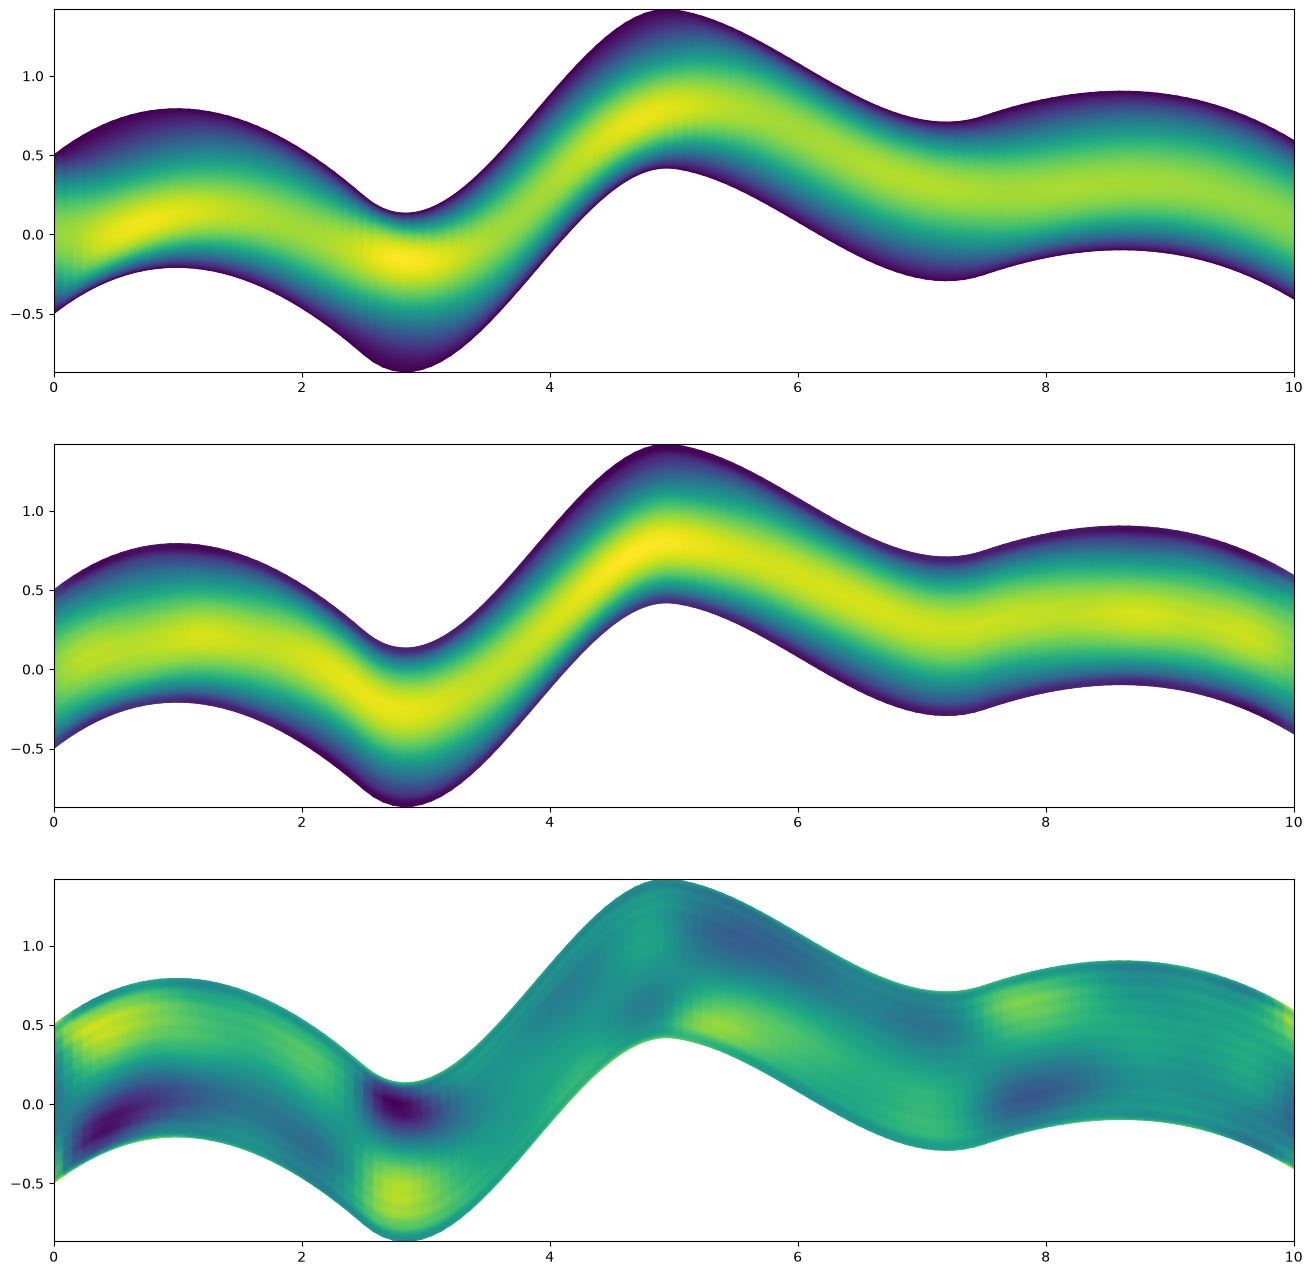

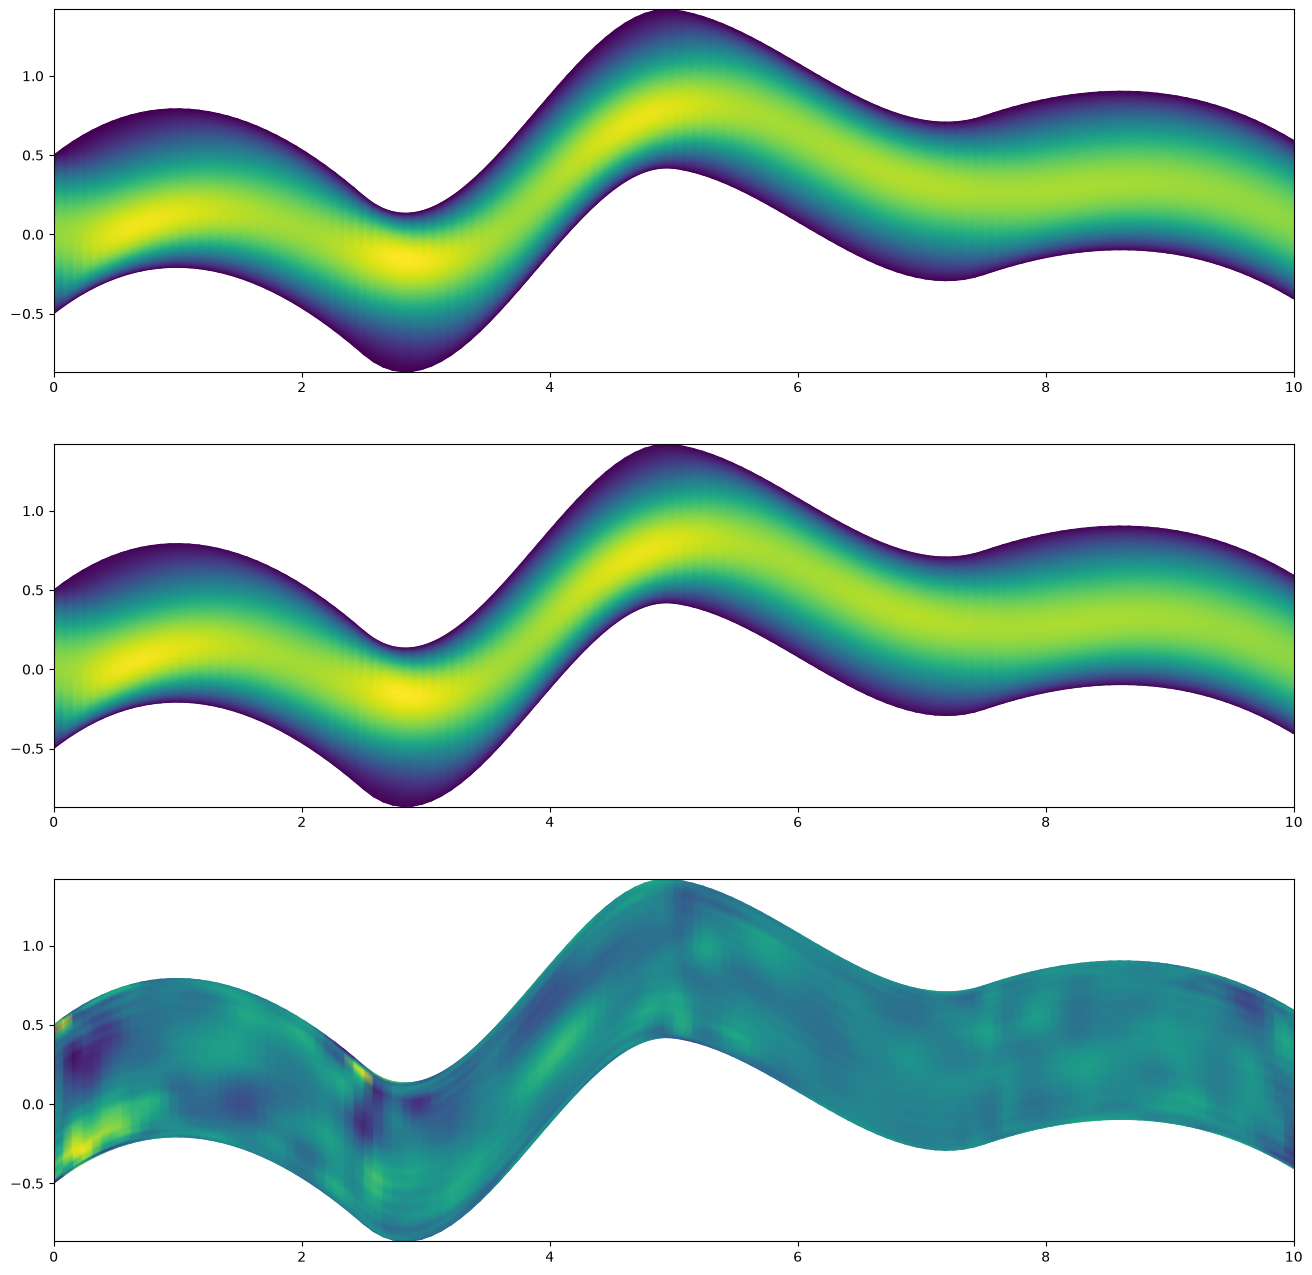

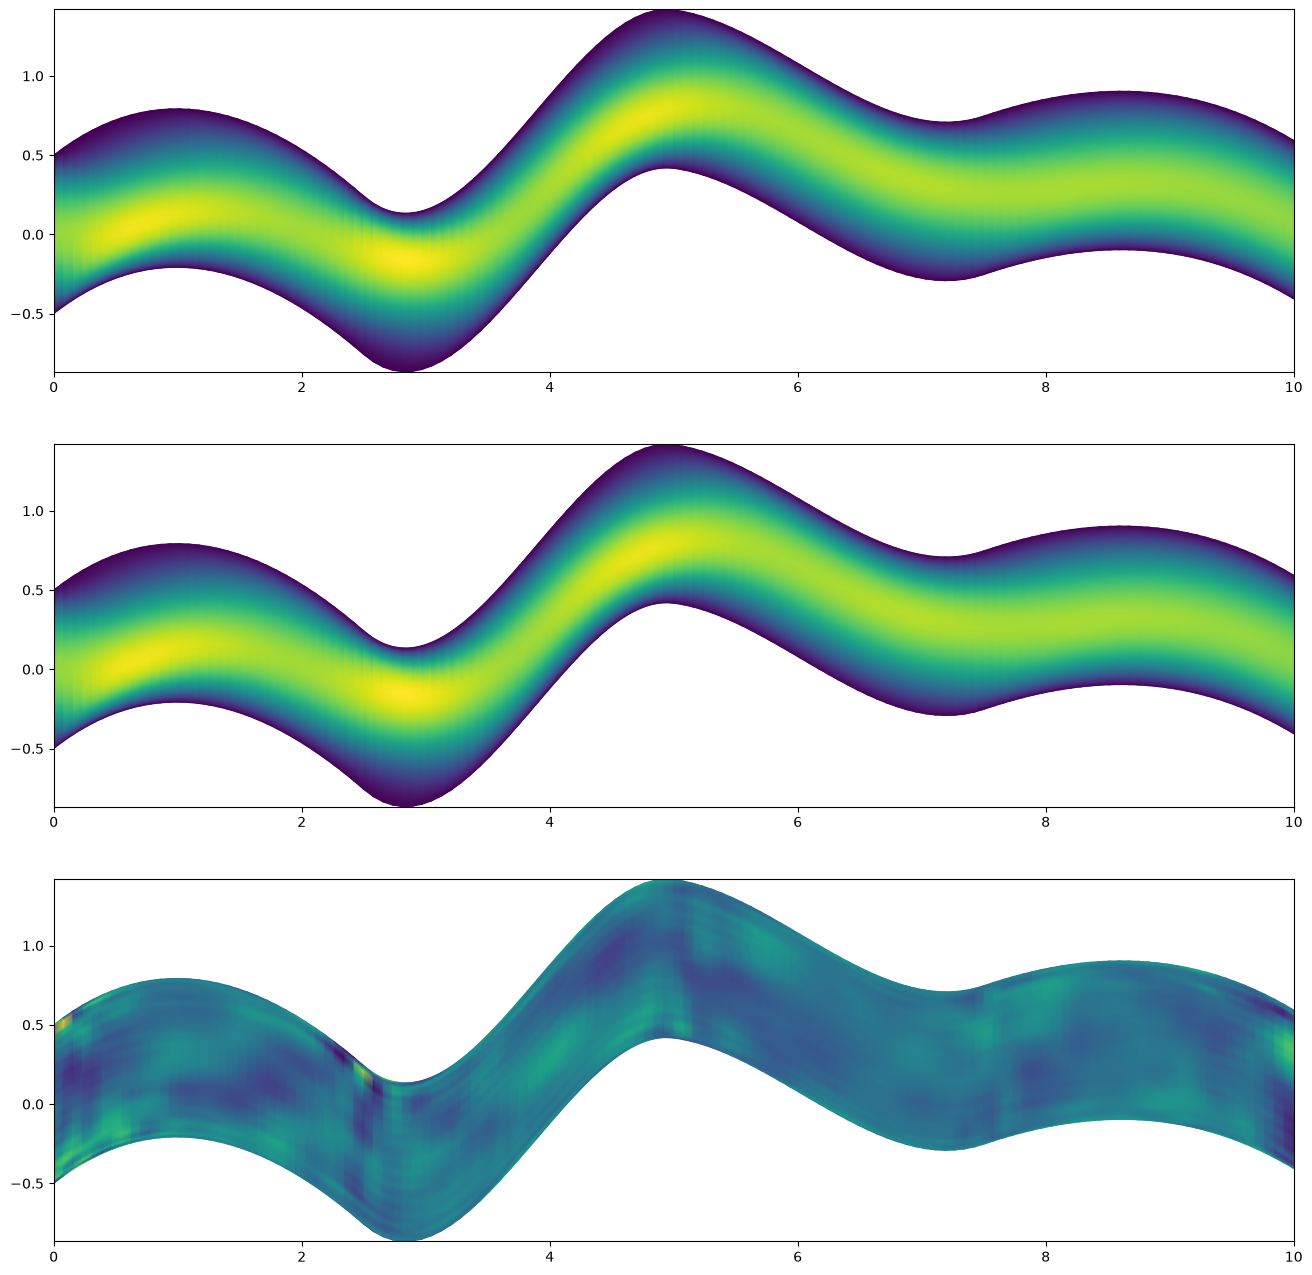

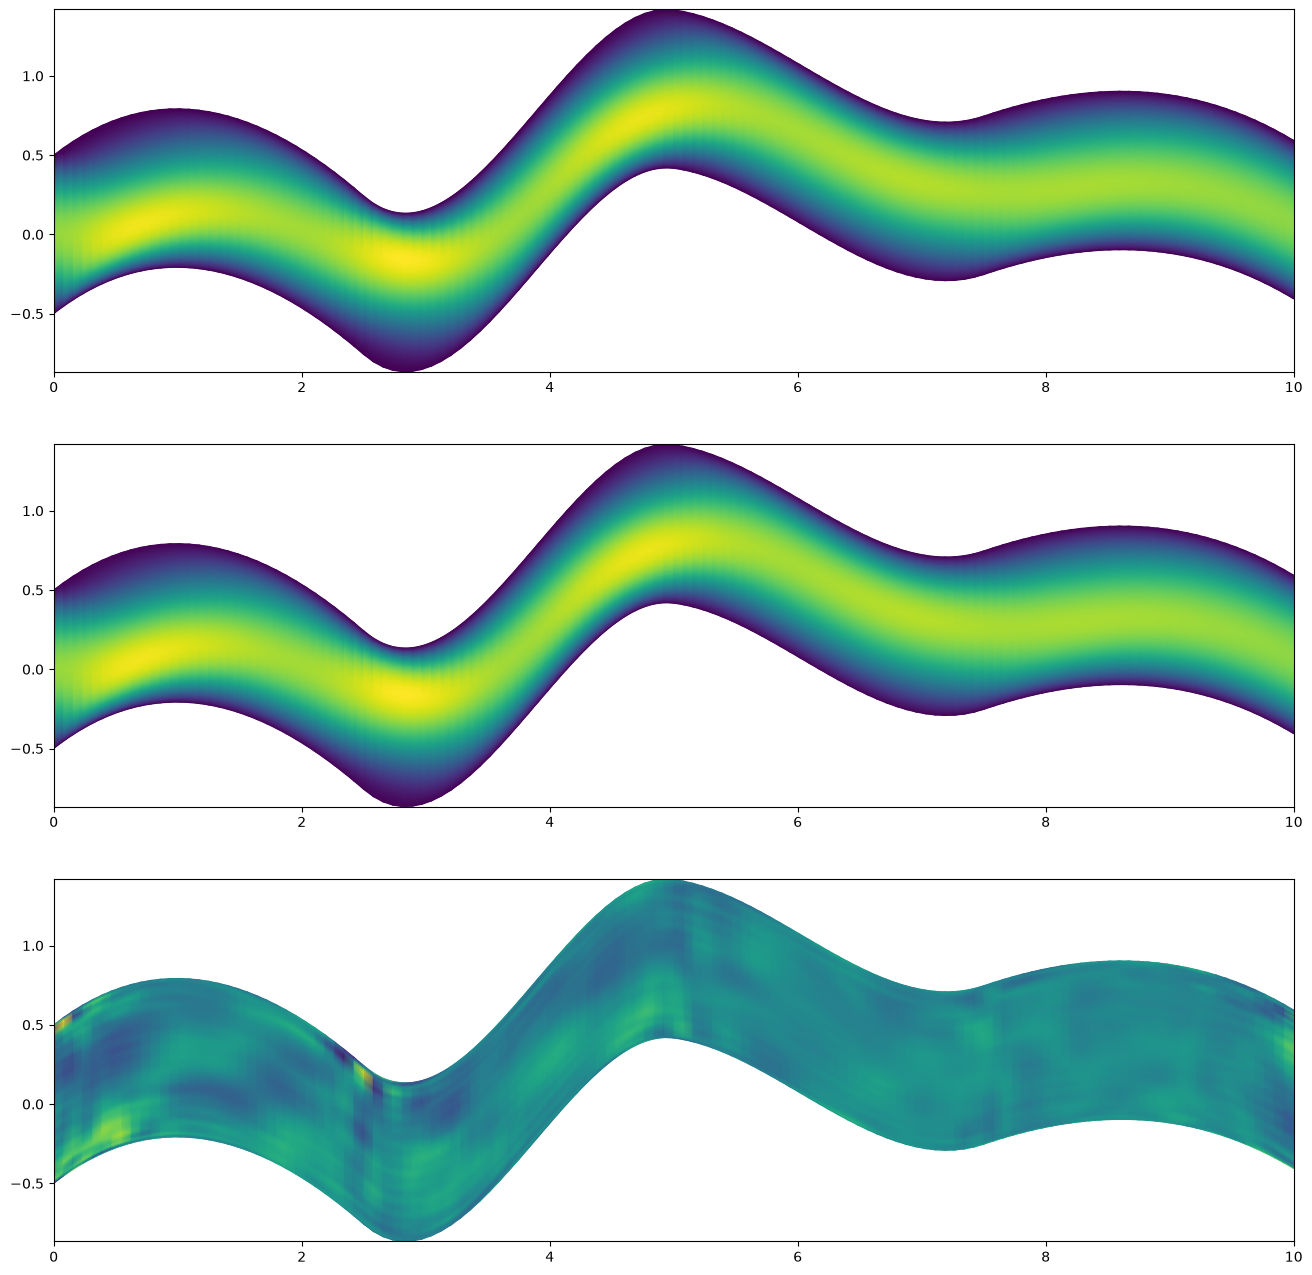

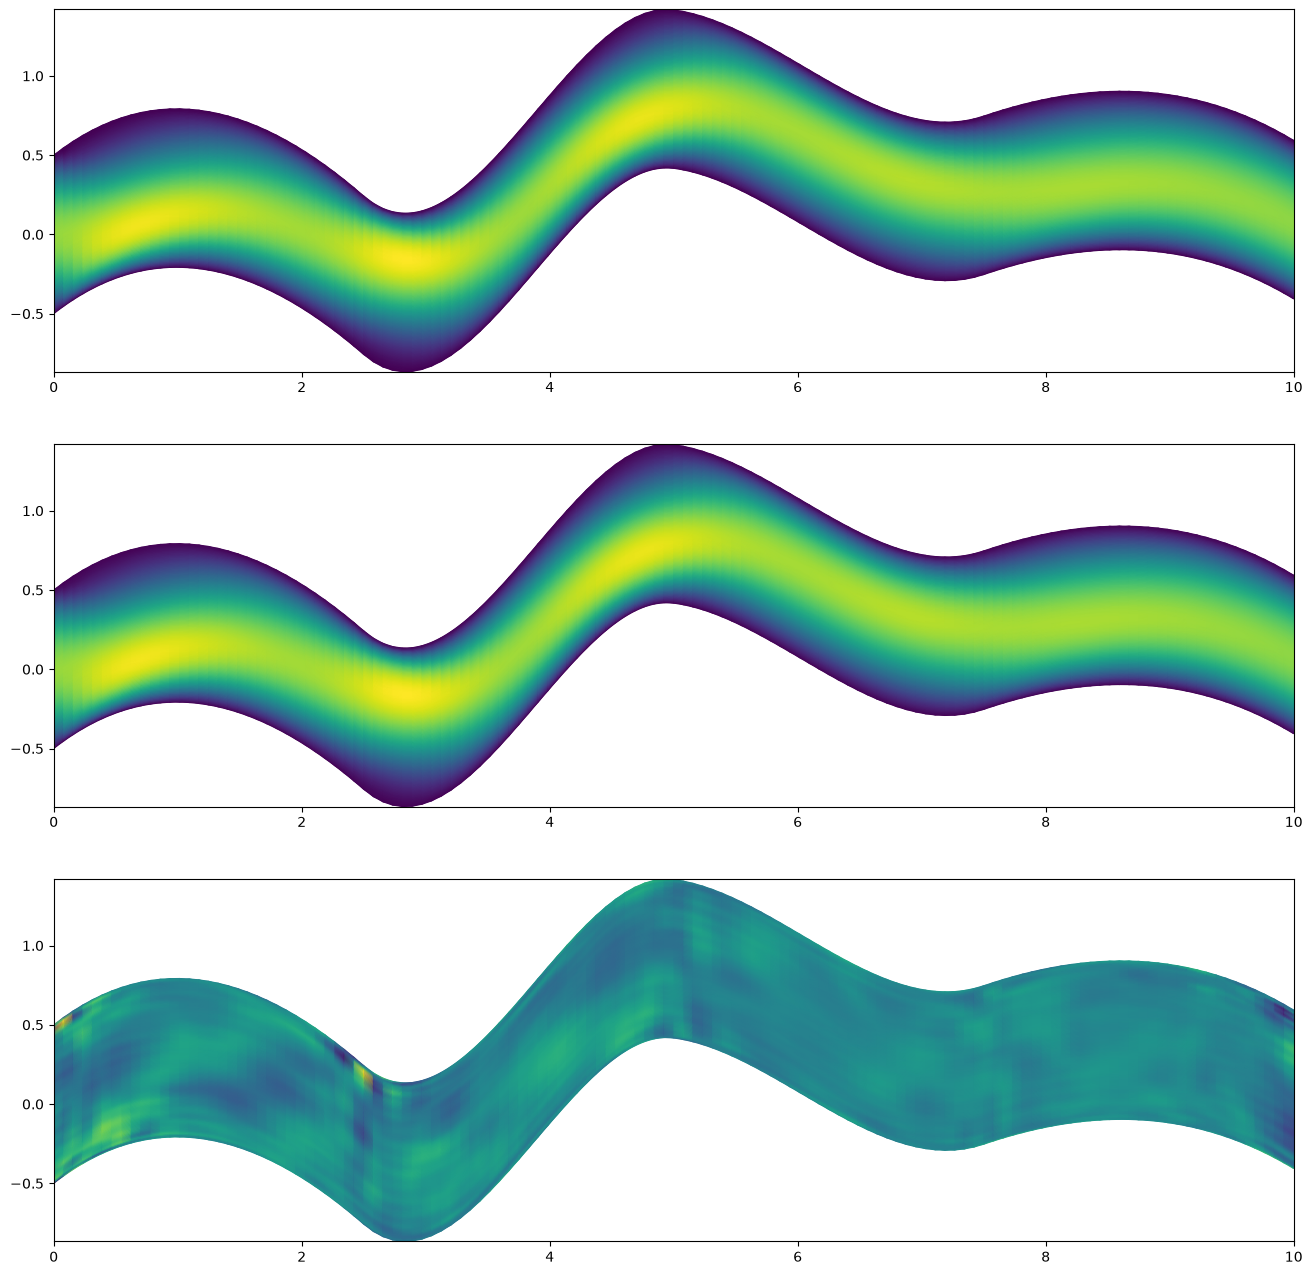

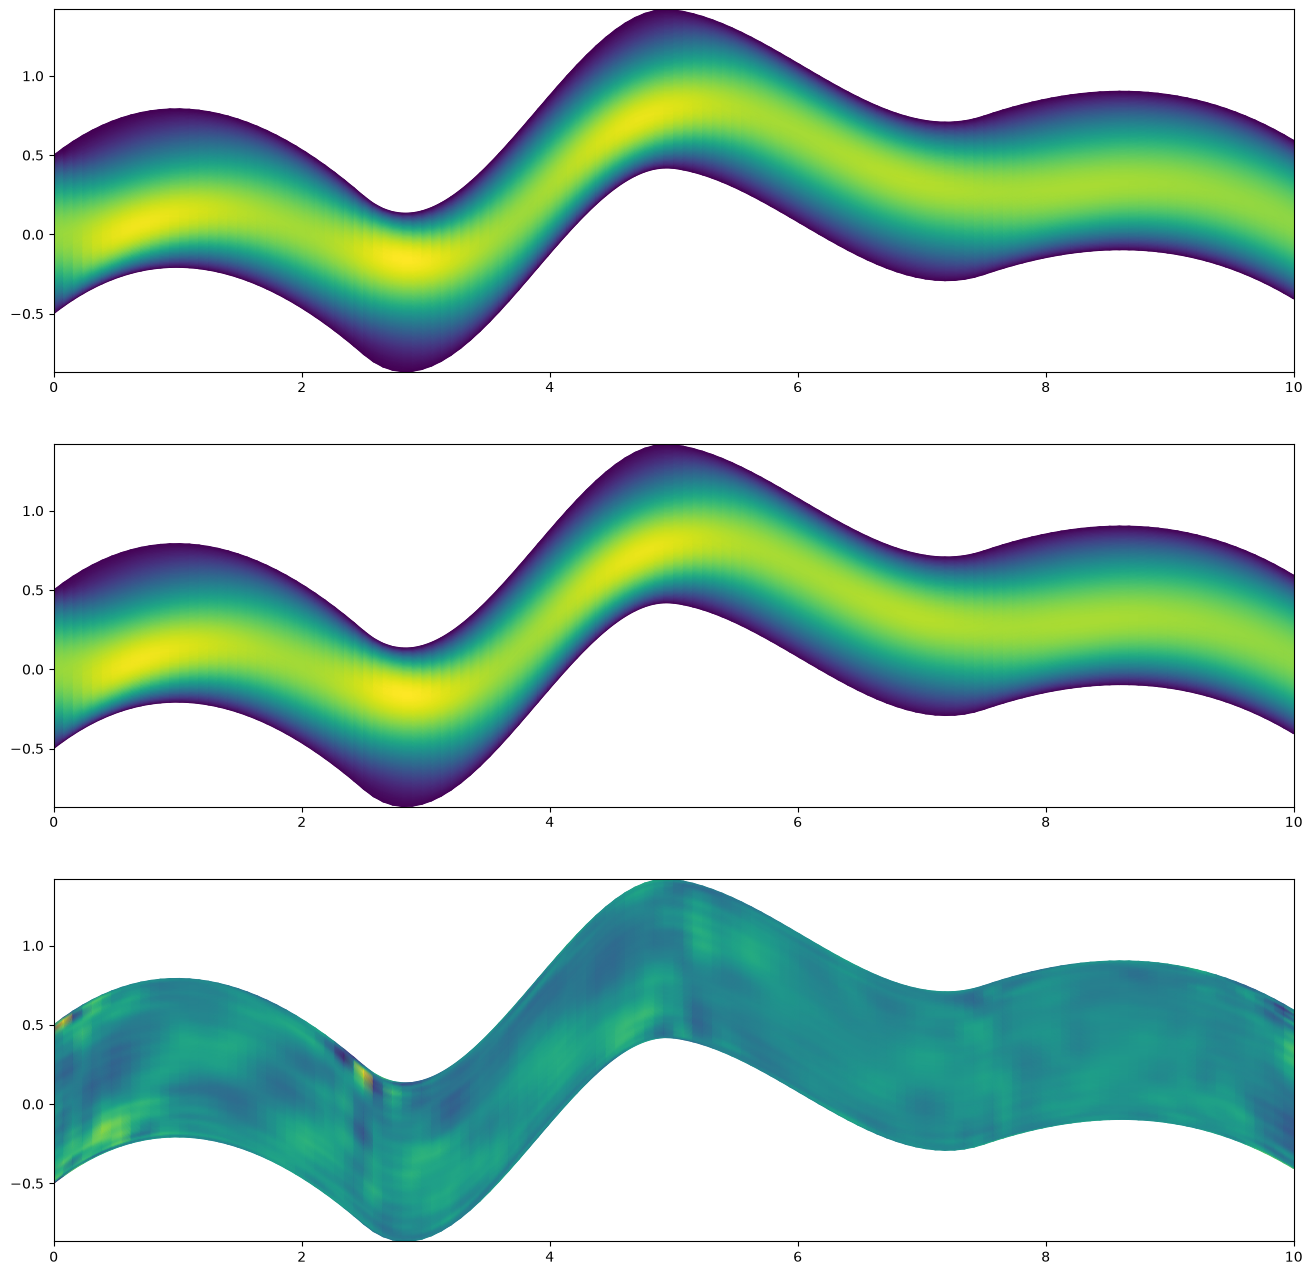

In [5]:
# 弯曲管道流场训练脚本。B 表示批大小，H/W 表示两个网格方向，C 表示通道。
# 各样本共享结构化网格的索引拓扑，物理 X/Y 坐标描述不同管道的几何形状。
# 模型在规则索引空间做 FFT，再将预测值对应回物理网格进行可视化。
"""
@author: Zongyi Li and Daniel Zhengyu Huang
"""

# F 提供 GELU、补零等函数；plt 用于训练期间的预测结果可视化。
import torch.nn.functional as F
import matplotlib.pyplot as plt
from timeit import default_timer
# 公共工具通过星号导入，还会带入其中的 torch、np、nn 等模块名。
from utilities3 import *
# 使用作者自定义的 Adam；其中复数梯度的二阶矩按 g * conj(g) 累积。
from Adam import Adam

# 固定 PyTorch、NumPy 和 CUDA 随机种子，便于比较重复实验。
# cuDNN 的确定性设置针对其支持的算子，不代表全部硬件上的结果逐位相同。
torch.manual_seed(0)
np.random.seed(0)
torch.cuda.manual_seed(0)
torch.backends.cudnn.deterministic = True

################################################################
# fourier layer
################################################################
# 二维谱卷积：输入 [B,Cin,H,W]，输出 [B,Cout,H,W]。
# 对空间维做 FFT，在选定的低频位置混合通道，再逆变换回空间域。
class SpectralConv2d(nn.Module):
    def __init__(self, in_channels, out_channels, modes1, modes2):
        super(SpectralConv2d, self).__init__()

        """
        2D Fourier layer. It does FFT, linear transform, and Inverse FFT.    
        """

        # in_channels/out_channels 是特征通道数，modes1/modes2 是保留的频率数。
        self.in_channels = in_channels
        self.out_channels = out_channels
        # rfft2 仅压缩最后一个空间维；第一个空间维仍保留正、负频率。
        # 因此第一个方向分别选取频谱开头和末尾的低频区域。
        self.modes1 = modes1  # Number of Fourier modes to multiply, at most floor(N/2) + 1
        self.modes2 = modes2

        # 缩小随机权重的初始化幅度，避免初始谱卷积输出过大。
        self.scale = (1 / (in_channels * out_channels))
        # 权重形状为 [Cin,Cout,modes1,modes2]，每个频率位置有独立的通道混合矩阵。
        # 傅里叶系数是复数，因此可学习权重也使用 torch.cfloat。
        self.weights1 = nn.Parameter(
            self.scale * torch.rand(in_channels, out_channels, self.modes1, self.modes2, dtype=torch.cfloat))
        # 第二组权重用于第一个空间方向的负频率区域，与第一组独立学习。
        self.weights2 = nn.Parameter(
            self.scale * torch.rand(in_channels, out_channels, self.modes1, self.modes2, dtype=torch.cfloat))

    # Complex multiplication
    # einsum 中 i 是输入通道、o 是输出通道，x/y 是频率索引；仅对 i 求和。
    # 不同频率之间不做混合，每个频率分别执行一次复数矩阵乘法。
    def compl_mul2d(self, input, weights):
        # (batch, in_channel, x,y ), (in_channel, out_channel, x,y) -> (batch, out_channel, x,y)
        return torch.einsum("bixy,ioxy->boxy", input, weights)

    def forward(self, x):
        # 此处 x 的布局为 [B,Cin,H,W]，B 为当前批次的样本数。
        batchsize = x.shape[0]
        # Compute Fourier coeffcients up to factor of e^(- something constant)
        # 对最后两个维度做二维实数 FFT，得到 [B,Cin,H,W//2+1] 的复数频谱。
        x_ft = torch.fft.rfft2(x)

        # Multiply relevant Fourier modes
        # 创建输出频谱；未写入的频率保持为零，相当于对这一分支做频率截断。
        out_ft = torch.zeros(batchsize, self.out_channels, x.size(-2), x.size(-1) // 2 + 1, dtype=torch.cfloat,
                             device=x.device)
        # 保留第一个方向开头、第二个方向开头的低频块。
        out_ft[:, :, :self.modes1, :self.modes2] = \
            self.compl_mul2d(x_ft[:, :, :self.modes1, :self.modes2], self.weights1)
        # 第一个方向的负频率位于数组末尾，因此还需写入这个频率块。
        out_ft[:, :, -self.modes1:, :self.modes2] = \
            self.compl_mul2d(x_ft[:, :, -self.modes1:, :self.modes2], self.weights2)

        # Return to physical space
        # 逆 FFT 恢复实数特征场；s 显式指定原尺寸，确保奇数宽度也能正确恢复。
        x = torch.fft.irfft2(out_ft, s=(x.size(-2), x.size(-1)))
        return x


# 整体 FNO：坐标特征提升维度 -> 四层谱卷积/逐点线性分支 -> 标量输出。
# 本脚本实际输入为物理坐标 [X,Y]，并额外拼接计算网格坐标，共 4 个通道。
class FNO2d(nn.Module):
    def __init__(self, modes1, modes2, width):
        super(FNO2d, self).__init__()

        """
        The overall network. It contains 4 layers of the Fourier layer.
        1. Lift the input to the desire channel dimension by self.fc0 .
        2. 4 layers of the integral operators u' = (W + K)(u).
            W defined by self.w; K defined by self.conv .
        3. Project from the channel space to the output space by self.fc1 and self.fc2 .

        input: the solution of the coefficient function and locations (a(x, y), x, y)
        input shape: (batchsize, x=s, y=s, c=3)
        output: the solution 
        output shape: (batchsize, x=s, y=s, c=1)
        """

        self.modes1 = modes1
        self.modes2 = modes2
        self.width = width
        # 在空间维补 8 个零，为 FFT 的周期延拓留出缓冲，输出前再裁去。
        self.padding = 8  # pad the domain if input is non-periodic
        # 这里实际接收 [X,Y,xi,eta] 四个通道；原英文模板中的 3 通道说明
        # 不对应本脚本的数据。Linear 作用于最后一维，输出 width 维特征。
        self.fc0 = nn.Linear(4, self.width)  # input channel is 3: (a(x, y), x, y)

        # 四个谱卷积分支在频域建模全局空间关系。
        self.conv0 = SpectralConv2d(self.width, self.width, self.modes1, self.modes2)
        self.conv1 = SpectralConv2d(self.width, self.width, self.modes1, self.modes2)
        self.conv2 = SpectralConv2d(self.width, self.width, self.modes1, self.modes2)
        self.conv3 = SpectralConv2d(self.width, self.width, self.modes1, self.modes2)
        # 1×1 卷积只混合当前位置的通道，对应公式中的局部线性分支 W。
        self.w0 = nn.Conv2d(self.width, self.width, 1)
        self.w1 = nn.Conv2d(self.width, self.width, 1)
        self.w2 = nn.Conv2d(self.width, self.width, 1)
        self.w3 = nn.Conv2d(self.width, self.width, 1)

        # 输出投影逐点执行 width -> 128 -> 1，得到每个网格点的一个标量。
        self.fc1 = nn.Linear(self.width, 128)
        self.fc2 = nn.Linear(128, 1)

    def forward(self, x):
        # 输入 x 为 [B,H,W,2]，其中两个通道分别是该样本的物理 X/Y 坐标。
        grid = self.get_grid(x.shape, x.device)
        # grid 是规则计算网格坐标 [xi,eta]；拼接后 x 变为 [B,H,W,4]。
        x = torch.cat((x, grid), dim=-1)
        # 提升通道数：[B,H,W,4] -> [B,H,W,width]。
        x = self.fc0(x)
        # 调整为卷积使用的布局 [B,width,H,W]；permute 仅改变维度顺序。
        x = x.permute(0, 3, 1, 2)

        # F.pad 的参数顺序是 [W左,W右,H上,H下]，这里仅在两个方向的末端补零。
        x = F.pad(x, [0, self.padding, 0, self.padding])

        # 第一层：谱分支 K(x) 负责全局关系，逐点分支 W(x) 补充局部通道变换。
        x1 = self.conv0(x)
        x2 = self.w0(x)
        # 两个分支形状一致，逐元素相加后通过 GELU 引入非线性。
        x = x1 + x2
        x = F.gelu(x)

        # 第二层继续对上一层特征执行同样的 K(x) + W(x) 结构。
        x1 = self.conv1(x)
        x2 = self.w1(x)
        x = x1 + x2
        x = F.gelu(x)

        # 第三层谱卷积与逐点线性变换。
        x1 = self.conv2(x)
        x2 = self.w2(x)
        x = x1 + x2
        x = F.gelu(x)

        # 第四层相加后不立即使用 GELU，随后进入输出投影。
        x1 = self.conv3(x)
        x2 = self.w3(x)
        x = x1 + x2

        # 裁掉补零部分，恢复原来的 H/W；随后将通道维移回最后一维。
        x = x[..., :-self.padding, :-self.padding]
        x = x.permute(0, 2, 3, 1)
        # 逐网格点执行两层全连接映射，最终输出形状为 [B,H,W,1]。
        x = self.fc1(x)
        x = F.gelu(x)
        x = self.fc2(x)
        return x

    # 生成与物理坐标不同的计算坐标：沿两个网格索引方向均匀覆盖 [0,1]。
    def get_grid(self, shape, device):
        batchsize, size_x, size_y = shape[0], shape[1], shape[2]
        gridx = torch.tensor(np.linspace(0, 1, size_x), dtype=torch.float)
        # 把一维 xi 扩展到所有样本和所有列，形状为 [B,H,W,1]。
        gridx = gridx.reshape(1, size_x, 1, 1).repeat([batchsize, 1, size_y, 1])
        gridy = torch.tensor(np.linspace(0, 1, size_y), dtype=torch.float)
        # 把一维 eta 扩展到所有样本和所有行，形状同样为 [B,H,W,1]。
        gridy = gridy.reshape(1, 1, size_y, 1).repeat([batchsize, size_x, 1, 1])
        # 拼接为 [B,H,W,2]，并移动到与输入相同的设备。
        return torch.cat((gridx, gridy), dim=-1).to(device)


################################################################
# configs
################################################################
# 原始数据路径相对于程序启动时的工作目录解析。
INPUT_X = './pipe/Pipe_X.npy'
INPUT_Y = './pipe/Pipe_Y.npy'
OUTPUT_Sigma = './pipe/Pipe_Q.npy'

# 仅使用前 N=1200 个样本，其中前 1000 个训练，最后 200 个测试。
ntrain = 1000
ntest = 200
N = 1200

# 每批 20 个样本，初始学习率为 0.001。
batch_size = 20
learning_rate = 0.001

# 训练 501 轮；每完成 100 轮，学习率乘以 0.5。
epochs = 501
step_size = 100
gamma = 0.5

# 两个网格方向各使用 modes=12 个模态；隐藏特征通道数为 width=32。
modes = 12
width = 32

# r1/r2 是网格下采样步长；s1/s2 根据原始 129×129 网格计算保留尺寸。
r1 = 1
r2 = 1
s1 = int(((129 - 1) / r1) + 1)
s2 = int(((129 - 1) / r2) + 1)

################################################################
# load data and data normalization
################################################################
# 读取各样本的物理坐标并转换为 float32。
# 虽然上方英文标题提到 normalization，这段实际没有执行归一化。
inputX = np.load(INPUT_X)
inputX = torch.tensor(inputX, dtype=torch.float)
inputY = np.load(INPUT_Y)
inputY = torch.tensor(inputY, dtype=torch.float)
# 把 X/Y 堆叠到最后一维，得到 [N,H,W,2] 的几何输入。
input = torch.stack([inputX, inputY], dim=-1)

# Q 的布局按 [N,C,H,W] 使用，[:,0] 选择第 1 个输出通道。
# 通道的具体物理含义取决于数据集定义；此处模型只预测这一标量场。
output = np.load(OUTPUT_Sigma)[:, 0]
output = torch.tensor(output, dtype=torch.float)

# 先限定前 N 个样本，再划分训练/测试集，并对两个空间维下采样。
# 在默认 ntrain=1000、ntest=200、N=1200 的配置下，两组样本不重叠。
x_train = input[:N][:ntrain, ::r1, ::r2][:, :s1, :s2]
y_train = output[:N][:ntrain, ::r1, ::r2][:, :s1, :s2]
x_test = input[:N][-ntest:, ::r1, ::r2][:, :s1, :s2]
y_test = output[:N][-ntest:, ::r1, ::r2][:, :s1, :s2]
# 输入整理为 [样本数,s1,s2,2]，目标 y 的形状为 [样本数,s1,s2]。
x_train = x_train.reshape(ntrain, s1, s2, 2)
x_test = x_test.reshape(ntest, s1, s2, 2)

# 坐标网格和参考场组成样本对；训练集每轮打乱，测试集保持顺序。
train_loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(x_train, y_train), batch_size=batch_size,
                                           shuffle=True)
test_loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(x_test, y_test), batch_size=batch_size,
                                          shuffle=False)
# 另建 batch_size=1 的测试加载器；本文件后续训练循环未使用它。
test_loader2 = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(x_test, y_test), batch_size=1,
                                          shuffle=False)

################################################################
# training and evaluation
################################################################
# 管道实验两个方向使用相同的 modes；原代码将模型放到 CUDA 上。
model = FNO2d(modes, modes, width).cuda()
# 按张量元素数统计参数；一个复数元素在 count_params 中计为一个。
print(count_params(model))

# 使用作者的 Adam 更新参数；weight_decay 是加入梯度的 L2 惩罚。
optimizer = Adam(model.parameters(), lr=learning_rate, weight_decay=1e-4)
# StepLR 根据已经完成的 epoch 数调节学习率。
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=step_size, gamma=gamma)

# 默认调用相对 L2 损失；size_average=False 表示先对 batch 内样本求和。
myloss = LpLoss(size_average=False)

# 每轮依次执行训练、学习率更新、测试和可选绘图。
for ep in range(epochs):
    # 切换到训练模式，并统计本轮累计损失和耗时。
    model.train()
    t1 = default_timer()
    train_l2 = 0
    for x, y in train_loader:
        # 把输入和参考场移动到 GPU，与模型处于相同设备。
        x, y = x.cuda(), y.cuda()

        # 清空上一批次的梯度，避免不同 batch 的梯度累积。
        optimizer.zero_grad()
        # 前向传播得到 [B,s1,s2,1] 的预测。
        out = model(x)

        # 分别展平成 [batch_size,网格点数]，按样本计算 ||预测-参考||₂ / ||参考||₂。
        # 这里按固定 batch_size 展平；默认样本数均可被 20 整除。
        loss = myloss(out.view(batch_size, -1), y.view(batch_size, -1))
        # 反向传播损失，自动计算所有可训练参数的梯度。
        loss.backward()

        # 更新参数；item() 将损失取为 Python 标量，用于累计而不保留计算图。
        optimizer.step()
        train_l2 += loss.item()

    # 一个 epoch 更新一次学习率，调用次序位于参数更新之后。
    scheduler.step()

    # 切换到评估模式，测试阶段只计算误差，不进行反向传播。
    model.eval()
    test_l2 = 0.0
    # no_grad 关闭梯度记录，减少测试阶段的内存开销。
    with torch.no_grad():
        for x, y in test_loader:
            x, y = x.cuda(), y.cuda()

            out = model(x)

            # 每个测试 batch 返回逐样本相对误差之和，随后累计到 test_l2。
            test_l2 += myloss(out.view(batch_size, -1), y.view(batch_size, -1)).item()

    # 累计误差分别除以训练和测试样本数，得到平均相对 L2 误差。
    train_l2 /= ntrain
    test_l2 /= ntest

    t2 = default_timer()
    # 依次打印 epoch、耗时、训练平均误差、测试平均误差。
    print(ep, t2 - t1, train_l2, test_l2)

    # ep 从 0 开始，因此第 0、100、200...轮绘图；模型保存语句保持注释状态。
    if ep%step_size==0:
        # torch.save(model, '../model/pipe_' + str(ep))
        # 使用最后一个测试 batch 的第一个样本；在其物理 X/Y 坐标上绘图。
        # detach 脱离计算图，cpu 移到主机，numpy 转为绘图数组。
        X = x[0, :, :, 0].squeeze().detach().cpu().numpy()
        Y = x[0, :, :, 1].squeeze().detach().cpu().numpy()
        truth = y[0].squeeze().detach().cpu().numpy()
        pred = out[0].squeeze().detach().cpu().numpy()

        # 三行依次显示参考场、预测场和带符号误差 pred-truth。
        fig, ax = plt.subplots(nrows=3, figsize=(16, 16))
        ax[0].pcolormesh(X, Y, truth, shading='gouraud')
        ax[1].pcolormesh(X, Y, pred, shading='gouraud')
        ax[2].pcolormesh(X, Y, pred-truth, shading='gouraud')
        # 显示图形；这段原代码没有将图片保存到文件。
        fig.savefig("pipe.png")
        

# utilities3

In [6]:
# Geo-FNO 公共工具：数据读取、归一化、Lp 损失、辅助网络和分布距离。
# 除特别说明外，张量第一维 N/B 表示样本，其余维度表示空间、时间或通道。
# 归一化统计量应由训练集估计，再用于测试集；导入模块本身不会执行归一化。
import torch
import numpy as np
import scipy.io
import h5py
import torch.nn as nn

# operator.mul 与 reduce 用于最后的参数维度连乘统计。
import operator
from functools import reduce
#################################################
#
# Utilities
#
#################################################
# 根据 CUDA 可用性提供默认设备变量；本变量不会自动移动模型或数据。
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# reading data
# 统一读取传统 MAT、MATLAB v7.3 MAT 和普通 HDF5 文件。
class MatReader(object):
    # to_torch 控制是否转为 Tensor，to_cuda 控制 Tensor 是否转到 GPU，
    # to_float 控制是否将读取的数组转换为 float32。
    def __init__(self, file_path, to_torch=True, to_cuda=False, to_float=True):
        super(MatReader, self).__init__()

        self.to_torch = to_torch
        self.to_cuda = to_cuda
        self.to_float = to_float

        self.file_path = file_path

        # data 保存变量字典或 HDF5 文件对象；两个标志区分不同读取方式。
        self.data = None
        self.old_mat = True
        self.h5 = False
        self._load_file()

    def _load_file(self):

        # 普通 .h5 文件直接交给 h5py，数据以 Dataset 形式保存。
        if self.file_path[-3:] == '.h5':
            self.data = h5py.File(self.file_path, 'r')
            self.h5 = True

        else:
            try:
                # 传统 MAT 文件由 scipy.io.loadmat 读取，结果可按变量名索引。
                self.data = scipy.io.loadmat(self.file_path)
            except:
                # 若 scipy 读取失败，尝试 HDF5 路径，以兼容 MATLAB v7.3。
                self.data = h5py.File(self.file_path, 'r')
                self.old_mat = False

    # 修改文件路径并重新加载；格式标志的更新方式保持原实现。
    def load_file(self, file_path):
        self.file_path = file_path
        self._load_file()

    # field 是文件中的变量名，例如 input/output；返回一个字段的数据。
    def read_field(self, field):
        x = self.data[field]

        if self.h5:
            # [()] 将 HDF5 Dataset 的内容读入内存中的 NumPy 数组。
            x = x[()]

        # 按 HDF5 方式读取的 MAT 文件需要反转轴顺序，以恢复 MATLAB 变量的布局。
        # 普通 .h5 分支不会执行这一步轴反转。
        if not self.old_mat:
            x = x[()]
            x = np.transpose(x, axes=range(len(x.shape) - 1, -1, -1))

        # 默认转为实数单精度，以匹配本项目训练数据和模型的常用精度。
        if self.to_float:
            x = x.astype(np.float32)

        if self.to_torch:
            # NumPy 数组转换为 PyTorch Tensor；GPU 转移只在 to_torch=True 时执行。
            x = torch.from_numpy(x)

            if self.to_cuda:
                x = x.cuda()

        return x

    # 这三个 setter 只修改后续读取的配置，不会转换此前返回的数组。
    def set_cuda(self, to_cuda):
        self.to_cuda = to_cuda

    def set_torch(self, to_torch):
        self.to_torch = to_torch

    def set_float(self, to_float):
        self.to_float = to_float

# normalization, pointwise gaussian
# 逐位置标准化：每个空间点/特征分别统计训练样本的均值和标准差。
# 例如 x=[N,H,W]，沿 N 维统计后 mean/std 均为 [H,W]。
class UnitGaussianNormalizer(object):
    def __init__(self, x, eps=0.00001):
        super(UnitGaussianNormalizer, self).__init__()

        # x could be in shape of ntrain*n or ntrain*T*n or ntrain*n*T
        # 只沿第 0 维统计；后续 encode/decode 利用广播支持不同大小的 batch。
        self.mean = torch.mean(x, 0)
        self.std = torch.std(x, 0)
        # eps 加到标准差上，避免零标准差导致直接除零。
        self.eps = eps

    # 标准化公式 z=(x-mean)/(std+eps)，不改变输入的维度布局。
    def encode(self, x):
        x = (x - self.mean) / (self.std + self.eps)
        return x

    # 反标准化公式 x=z*(std+eps)+mean；sample_idx 可指定仅恢复部分位置。
    def decode(self, x, sample_idx=None):
        if sample_idx is None:
            std = self.std + self.eps # n
            mean = self.mean
        else:
            # 保留原代码对索引形状的判断：此分支直接在统计量上按 sample_idx 取值。
            if len(self.mean.shape) == len(sample_idx[0].shape):
                std = self.std[sample_idx] + self.eps  # batch*n
                mean = self.mean[sample_idx]
            # 此分支保留统计量的第一个维度，再按 sample_idx 选择后续位置；
            # 调用时的索引格式和数据布局需要与该分支一致。
            if len(self.mean.shape) > len(sample_idx[0].shape):
                std = self.std[:,sample_idx]+ self.eps # T*batch*n
                mean = self.mean[:,sample_idx]

        # x is in shape of batch*n or T*batch*n
        x = (x * std) + mean
        return x

    # 归一化器不是 nn.Module，统计量需单独移动；这里原地更新 mean/std 属性。
    def cuda(self):
        self.mean = self.mean.cuda()
        self.std = self.std.cuda()

    # 将统计量移回 CPU；与 cuda() 一样，此方法没有显式返回新对象。
    def cpu(self):
        self.mean = self.mean.cpu()
        self.std = self.std.cpu()

# normalization, Gaussian
# 全局标准化：整个张量共用一个均值和一个标准差，区别于逐位置统计。
# 这种变换只调整位置和尺度，并不保证原始分布变为高斯分布。
class GaussianNormalizer(object):
    def __init__(self, x, eps=0.00001):
        super(GaussianNormalizer, self).__init__()

        # 没有指定 dim，因此对全部样本、空间位置和通道一起求统计量。
        self.mean = torch.mean(x)
        self.std = torch.std(x)
        self.eps = eps

    # 用同一组全局统计量对训练或测试数据编码。
    def encode(self, x):
        x = (x - self.mean) / (self.std + self.eps)
        return x

    # 恢复原始物理量；这里保留 sample_idx 参数，但实现中并未使用它。
    def decode(self, x, sample_idx=None):
        x = (x * (self.std + self.eps)) + self.mean
        return x

    # 将全局统计量移到 GPU；待处理张量也需要在同一设备。
    def cuda(self):
        self.mean = self.mean.cuda()
        self.std = self.std.cuda()

    # 将全局统计量移回 CPU。
    def cpu(self):
        self.mean = self.mean.cpu()
        self.std = self.std.cpu()


# normalization, scaling by range
# 逐特征 min-max 缩放：把训练集各位置的最小值映射到 low，最大值映射到 high。
class RangeNormalizer(object):
    def __init__(self, x, low=0.0, high=1.0):
        super(RangeNormalizer, self).__init__()
        # 沿样本维取最小/最大值，随后展平特征维；每个特征分别确定缩放系数。
        mymin = torch.min(x, 0)[0].view(-1)
        mymax = torch.max(x, 0)[0].view(-1)

        # 构造仿射变换 z=a*x+b；此处沿用原式，未对最大值等于最小值的情况加保护。
        self.a = (high - low)/(mymax - mymin)
        self.b = -self.a*mymax + high

    def encode(self, x):
        # 先记住原形状，再保留 batch 维展平，便于与一维的 a/b 做广播计算。
        s = x.size()
        x = x.view(s[0], -1)
        x = self.a*x + self.b
        # 把缩放后的特征恢复到输入的原始形状。
        x = x.view(s)
        return x

    # 使用 x=(z-b)/a 反向恢复物理量，展平和还原规则与 encode 相同。
    def decode(self, x):
        s = x.size()
        x = x.view(s[0], -1)
        x = (x - self.b)/self.a
        x = x.view(s)
        return x

#loss function with rel/abs Lp loss
# 按样本计算绝对/相对 Lp 误差；p=2 时对应 L2 范数，而不是 MSE。
# 默认调用 __call__ 会转入 rel，相对误差的参考量是第二个参数 y。
class LpLoss(object):
    def __init__(self, d=2, p=2, size_average=True, reduction=True):
        super(LpLoss, self).__init__()

        #Dimension and Lp-norm type are postive
        assert d > 0 and p > 0

        # d 是绝对误差积分近似的空间维度，p 是范数阶数。
        # reduction=False 返回逐样本误差；否则由 size_average 决定求均值还是求和。
        self.d = d
        self.p = p
        self.reduction = reduction
        self.size_average = size_average

    # 绝对 Lp 误差：用网格间距权重 h^(d/p) 将离散范数近似为连续范数。
    def abs(self, x, y):
        num_examples = x.size()[0]

        #Assume uniform mesh
        # 假设单位区间上的均匀网格，并由第一个空间方向计算 h。
        # 这一简化不包含非均匀曲线网格的单元面积或 Jacobian 权重。
        h = 1.0 / (x.size()[1] - 1.0)

        # 展平非 batch 维，对每个样本单独计算差值的 p 范数，结果形状为 [B]。
        all_norms = (h**(self.d/self.p))*torch.norm(x.reshape(num_examples,-1) - y.reshape(num_examples,-1), self.p, 1)

        # 按配置将 [B] 的逐样本误差求均值或求和；关闭 reduction 则直接返回数组。
        if self.reduction:
            if self.size_average:
                return torch.mean(all_norms)
            else:
                return torch.sum(all_norms)

        return all_norms

    # 相对 Lp 误差：先对每个样本求 ||x-y||p 和 ||y||p，再逐样本相除。
    def rel(self, x, y):
        num_examples = x.size()[0]

        # reshape 仅保留 batch 维，其余空间、时间或通道元素全部合并。
        diff_norms = torch.norm(x.reshape(num_examples,-1) - y.reshape(num_examples,-1), self.p, 1)
        y_norms = torch.norm(y.reshape(num_examples,-1), self.p, 1)

        # 这里先计算逐样本的相对误差，再汇总；不是把两个 batch 范数直接相除。
        # 原代码的分母没有 epsilon 保护，零参考场的处理方式也保持原样。
        if self.reduction:
            if self.size_average:
                return torch.mean(diff_norms/y_norms)
            else:
                return torch.sum(diff_norms/y_norms)

        return diff_norms/y_norms

    # 使实例可像函数一样调用：myloss(pred,target) 默认计算相对误差。
    def __call__(self, x, y):
        return self.rel(x, y)

# A simple feedforward neural network
# 普通多层感知机 MLP，与图像分类中具有密集连接结构的 DenseNet 不是同一网络。
class DenseNet(torch.nn.Module):
    # layers 给出各层宽度，如 [2,64,1]；nonlinearity 传激活函数类，如 nn.ReLU。
    # normalize 控制隐藏层的 BatchNorm1d，out_nonlinearity 控制最后的输出激活。
    def __init__(self, layers, nonlinearity, out_nonlinearity=None, normalize=False):
        super(DenseNet, self).__init__()

        # 相邻两个宽度定义一层 Linear，因此线性层数量等于宽度列表长度减一。
        self.n_layers = len(layers) - 1

        assert self.n_layers >= 1

        # ModuleList 注册各个子层，使参数能被优化器、state_dict 和设备迁移机制管理。
        self.layers = nn.ModuleList()

        for j in range(self.n_layers):
            self.layers.append(nn.Linear(layers[j], layers[j+1]))

            # 隐藏层按 Linear -> 可选 BatchNorm -> 激活排列；最后一个 Linear 默认不接激活。
            if j != self.n_layers - 1:
                if normalize:
                    self.layers.append(nn.BatchNorm1d(layers[j+1]))

                self.layers.append(nonlinearity())

        # 如果显式提供输出激活，则追加在整个网络末尾。
        if out_nonlinearity is not None:
            self.layers.append(out_nonlinearity())

    # 按注册顺序逐层计算输出，保留原来的模块组织方式。
    def forward(self, x):
        for _, l in enumerate(self.layers):
            x = l(x)

        return x

# 计算两组实数样本的两两距离：输入 [n1,d]、[n2,d]，输出 [n1,n2]。
# 以返回语句为准，结果是含 eps 平滑的距离，而非英文首句所说的距离平方。
def pdist(sample_1, sample_2, norm=2, eps=1e-5):
    r"""Compute the matrix of all squared pairwise distances.
    Arguments
    ---------
    sample_1 : torch.Tensor or Variable
        The first sample, should be of shape ``(n_1, d)``.
    sample_2 : torch.Tensor or Variable
        The second sample, should be of shape ``(n_2, d)``.
    norm : float
        The l_p norm to be used.
    Returns
    -------
    torch.Tensor or Variable
        Matrix of shape (n_1, n_2). The [i, j]-th entry is equal to
        ``|| sample_1[i, :] - sample_2[j, :] ||_p``."""
    n_1, n_2 = sample_1.size(0), sample_2.size(0)
    norm = float(norm)
    # 欧氏距离使用 ||a-b||²=||a||²+||b||²-2a·b，避免显式创建三维差值数组。
    if norm == 2.:
        norms_1 = torch.sum(sample_1**2, dim=1, keepdim=True)
        norms_2 = torch.sum(sample_2**2, dim=1, keepdim=True)
        norms = (norms_1.expand(n_1, n_2) +
                 norms_2.transpose(0, 1).expand(n_1, n_2))
        distances_squared = norms - 2 * sample_1.mm(sample_2.t())
        # abs 处理舍入产生的负值，再加 eps 开平方；同一点的距离因此约为 sqrt(eps)。
        return torch.sqrt(eps + torch.abs(distances_squared))
    else:
        # 其他 p 值通过广播形成 [n1,n2,d] 的两两差，再沿特征维求 p 范数。
        dim = sample_1.size(1)
        expanded_1 = sample_1.unsqueeze(1).expand(n_1, n_2, dim)
        expanded_2 = sample_2.unsqueeze(0).expand(n_1, n_2, dim)
        differences = torch.abs(expanded_1 - expanded_2) ** norm
        inner = torch.sum(differences, dim=2, keepdim=False)
        return (eps + inner) ** (1. / norm)

# 最大均值差异 MMD 的平方统计量，用于比较两组样本的分布。
# 采用多个高斯核的和；两组内部排除自身配对，有限样本估计可以为负。
# 当前翼型和管道训练脚本没有调用该工具。
class MMDStatistic:
    r"""The *unbiased* MMD test of :cite:`gretton2012kernel`.
    The kernel used is equal to:
    .. math ::
        k(x, x') = \sum_{j=1}^k e^{-\alpha_j\|x - x'\|^2},
    for the :math:`\alpha_j` proved in :py:meth:`~.MMDStatistic.__call__`.
    Arguments
    ---------
    n_1: int
        The number of points in the first sample.
    n_2: int
        The number of points in the second sample."""

    # n_1/n_2 固定两组样本数量；下方分母要求每组至少有两个样本。
    def __init__(self, n_1, n_2):
        self.n_1 = n_1
        self.n_2 = n_2

        # The three constants used in the test.
        # 分别对应组内均值项和跨组均值项的归一化系数。
        self.a00 = 1. / (n_1 * (n_1 - 1))
        self.a11 = 1. / (n_2 * (n_2 - 1))
        self.a01 = - 1. / (n_1 * n_2)

    def __call__(self, sample_1, sample_2, alphas, ret_matrix=False):
        r"""Evaluate the statistic.
        The kernel used is
        .. math::
            k(x, x') = \sum_{j=1}^k e^{-\alpha_j \|x - x'\|^2},
        for the provided ``alphas``.
        Arguments
        ---------
        sample_1: :class:`torch:torch.autograd.Variable`
            The first sample, of size ``(n_1, d)``.
        sample_2: variable of shape (n_2, d)
            The second sample, of size ``(n_2, d)``.
        alphas : list of :class:`float`
            The kernel parameters.
        ret_matrix: bool
            If set, the call with also return a second variable.
            This variable can be then used to compute a p-value using
            :py:meth:`~.MMDStatistic.pval`.
        Returns
        -------
        :class:`float`
            The test statistic.
        :class:`torch:torch.autograd.Variable`
            Returned only if ``ret_matrix`` was set to true."""
        # 把两组样本拼接后一次计算完整距离矩阵，包含组内和跨组距离。
        sample_12 = torch.cat((sample_1, sample_2), 0)
        distances = pdist(sample_12, sample_12, norm=2)

        kernels = None
        # alphas 控制高斯核的尺度；对各尺度 exp(-alpha*距离²) 相加。
        for alpha in alphas:
            kernels_a = torch.exp(- alpha * distances ** 2)
            if kernels is None:
                kernels = kernels_a
            else:
                kernels = kernels + kernels_a

        # 将完整核矩阵拆为第一组内部、第二组内部和跨组的三个子矩阵。
        k_1 = kernels[:self.n_1, :self.n_1]
        k_2 = kernels[self.n_1:, self.n_1:]
        k_12 = kernels[:self.n_1, self.n_1:]

        # MMD² = 第一组组内核均值 + 第二组组内核均值 - 2×跨组核均值。
        # 组内减去 trace，去掉每个样本与自身的配对。
        mmd = (2 * self.a01 * k_12.sum() +
               self.a00 * (k_1.sum() - torch.trace(k_1)) +
               self.a11 * (k_2.sum() - torch.trace(k_2)))
        # ret_matrix=True 时额外返回完整核矩阵；此类本身没有实现 pval 方法。
        if ret_matrix:
            return mmd, kernels
        else:
            return mmd

# print the number of parameters
# 按每个注册参数张量的维度连乘并求和；包含冻结参数，不包含 buffer。
# 沿用原统计口径：一个复数元素计为一个参数，若比较实数自由度则应计为两个。
def count_params(model):
    c = 0
    for p in list(model.parameters()):
        c += reduce(operator.mul, list(p.size()))
    return c
